#### Import important libraries needed to run analysis and set resolution for figures

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from datetime import datetime

from sklearn.preprocessing import TargetEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score


plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

In [2]:
# A few cells in this notebook do large searches or evaluations, which can slow down total runtime
# Set this variable to True to skip execution of these processes
speed_flag = False

## Project Statement

Airbnb's rental market is still new enough to not have some idealized perfectly elastic pricing scheme. We want to find if there is a way to predict pricing given a set of data about the listings in a given area. Airbnb provides data about listings which we will limit to New York City so the dataset will still be large, but reduced in its scope. We will explore additional data such as NYPD crime statistics and walkability metrics about locations within New York as ways to gauge relative attractiveness. If this model is successful, it could be useful for future hosts to figure out a competitive pricing for their rental spaces.

## Data Cleaning

Load initial data set and output

In [3]:
ny_listing_raw = pd.read_csv("data/listings.csv")
ny_listing_raw.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,2595,Skylit Studio Oasis | Midtown Manhattan Sanctuary,2845,Jennifer,Manhattan,Midtown,40.75356,-73.98559,Entire home/apt,240.0,30,47,2022-06-21,0.24,3,289,0,NaN
1,6848,Only 2 stops to Manhattan studio,15991,Allen,Brooklyn,Williamsburg,40.70935,-73.95342,Entire home/apt,96.0,30,195,2025-06-09,0.98,1,285,3,NaN
2,6872,Uptown Sanctuary w/ Private Bath (Month to Month),16104,Kahshanna,Manhattan,East Harlem,40.80107,-73.94255,Private room,59.0,30,1,2022-06-05,0.02,2,83,0,NaN
3,6990,UES Beautiful Blue Room,16800,Cynthia,Manhattan,East Harlem,40.78778,-73.94759,Private room,73.0,30,249,2025-05-27,1.28,1,186,4,NaN
4,7064,"Amazing location! Wburg. Large, bright & tranquil",17297,Joelle,Brooklyn,Williamsburg,40.71248,-73.95881,Private room,NaN,30,13,2022-09-12,0.07,2,0,0,NaN


In [4]:
ny_listing_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36111 entries, 0 to 36110
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              36111 non-null  int64  
 1   name                            36109 non-null  object 
 2   host_id                         36111 non-null  int64  
 3   host_name                       34945 non-null  object 
 4   neighbourhood_group             36111 non-null  object 
 5   neighbourhood                   36111 non-null  object 
 6   latitude                        36111 non-null  float64
 7   longitude                       36111 non-null  float64
 8   room_type                       36111 non-null  object 
 9   price                           21328 non-null  float64
 10  minimum_nights                  36111 non-null  int64  
 11  number_of_reviews               36111 non-null  int64  
 12  last_review                     

In [5]:
ny_listing_raw = ny_listing_raw.dropna(subset=['price'])

#### Data Cleaning : Id

In [6]:
## Check to see if the id is incremented unique id
print(ny_listing_raw['id'].nunique())

21328


Because ID is a unique counting id - use for joins but drop for modeling

In [7]:
drop_columns = ['id']

#### Data Cleaning : Name

In [8]:
ny_listing_raw['name'] = ny_listing_raw['name'].str.lower()
names = ny_listing_raw['name'].str.split(expand=True).stack()
counts = names.value_counts()
names_df = counts.reset_index()
names_df.columns = ['word','count']
print(names_df)


              word  count
0               in   5240
1             room   3757
2          private   2930
3          bedroom   2456
4                |   2109
...            ...    ...
11135      bedeoom      1
11136   room,great      1
11137        apt-4      1
11138  parkchester      1
11139           5f      1

[11140 rows x 2 columns]


In [9]:
names_df = names_df.loc[names_df['count'] > 1000]
print(names_df)

          word  count
0           in   5240
1         room   3757
2      private   2930
3      bedroom   2456
4            |   2109
5       studio   1833
6    apartment   1818
7            &   1813
8         cozy   1745
9           to   1571
10         the   1569
11        near   1489
12           2   1415
13        with   1413
14        park   1361
15    brooklyn   1322
16         apt   1172
17         nyc   1168
18           1   1143
19           -   1050
20  blueground   1037
21   manhattan   1023


Remove non-descriptive words and symbols

In [10]:
exclude_words=['of','and','to','the','with', 'in', 'a','room', 'bed', 'near','from']
names_df = names_df[~names_df['word'].isin(exclude_words)]
names_df = names_df[~names_df['word'].str.contains(r'[0-9!@#$%^&*()_+=\-\[\]{}|;:\'",.<>/?~`]', regex=True)]
print(names_df)

          word  count
2      private   2930
3      bedroom   2456
5       studio   1833
6    apartment   1818
8         cozy   1745
14        park   1361
15    brooklyn   1322
16         apt   1172
17         nyc   1168
20  blueground   1037
21   manhattan   1023


In [11]:
names_df.count()

word     11
count    11
dtype: int64

We won't use this for initial but will use possibly for feature engineering

In [12]:
drop_columns.append('name')

#### Data Cleaning : Host_id

In [13]:
print(ny_listing_raw['host_id'].nunique())

10418


<Axes: xlabel='Host Ids', ylabel='Occurrences'>

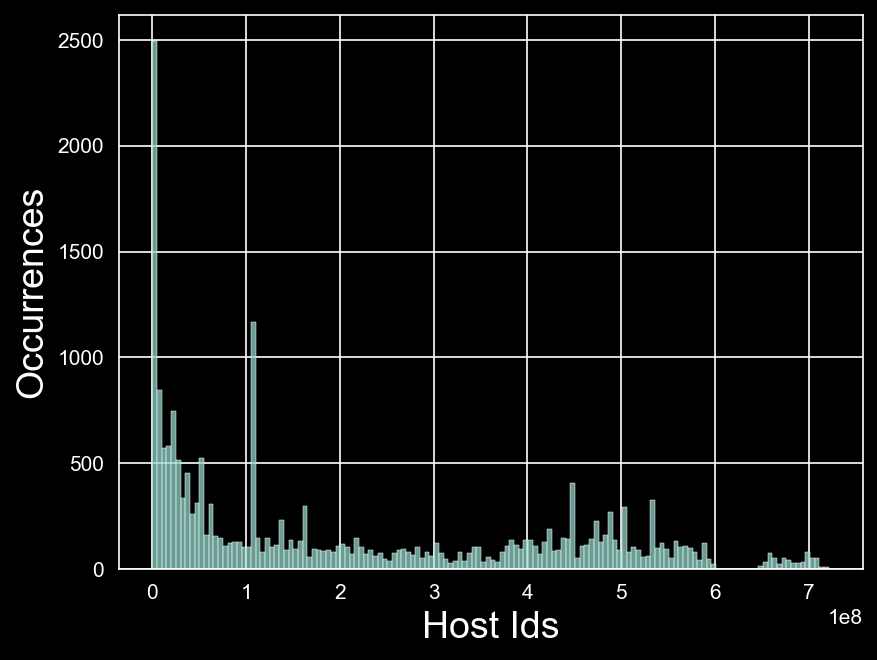

In [14]:
plt.xlabel("Host Ids", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['host_id'], bins='stone')

In [15]:
drop_columns.append('host_id')

#### Data Cleaning : Host_name

In [16]:
drop_columns.append('host_name')

#### Data Cleaning : neighbourhood_group           

In [17]:
print(set(ny_listing_raw["neighbourhood_group"]))

{'Manhattan', 'Bronx', 'Brooklyn', 'Queens', 'Staten Island'}


In [18]:
ny_listing_raw['neighbourhood_group'] = ny_listing_raw['neighbourhood_group'].fillna('Unknown') 

In [19]:
ny_listing_raw['neighbourhood_group'] = ny_listing_raw['neighbourhood_group'].astype('category')

<Axes: xlabel='Neighbourhood Group', ylabel='Count'>

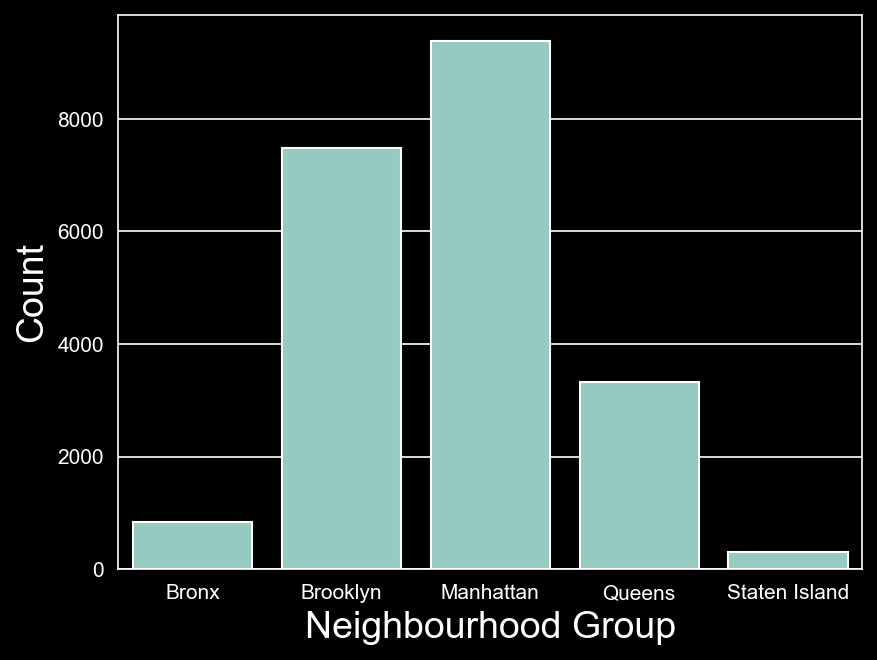

In [20]:
plt.xlabel("Neighbourhood Group", fontsize=18)
plt.ylabel("Count", fontsize=18)
sns.countplot(data=ny_listing_raw, x="neighbourhood_group")

#### Data Cleaning : neighbourhood

In [21]:
print(set(ny_listing_raw["neighbourhood"]))

{'Fieldston', 'Fort Hamilton', 'South Beach', 'Woodside', 'Fordham', 'Clinton Hill', 'Chelsea', 'Spuyten Duyvil', 'Roosevelt Island', 'Rosebank', 'Rockaway Beach', 'Financial District', 'Bayside', 'Fort Greene', 'Harlem', 'Mount Hope', 'Lower East Side', 'Borough Park', 'Mariners Harbor', 'Greenwich Village', 'Briarwood', 'Belle Harbor', 'Hollis Hills', 'Navy Yard', 'Flatbush', 'Flatiron District', 'Willowbrook', 'Little Neck', 'Gowanus', 'Sunset Park', 'Tompkinsville', 'Jamaica', 'Port Morris', 'West Farms', 'Clason Point', 'Howland Hook', 'Port Richmond', 'Jamaica Hills', 'Holliswood', 'Jackson Heights', 'Astoria', 'Morningside Heights', 'Downtown Brooklyn', 'Great Kills', 'Carroll Gardens', 'Riverdale', 'Claremont Village', 'Breezy Point', 'Pelham Bay', 'Sheepshead Bay', 'Grymes Hill', 'Far Rockaway', 'Bedford-Stuyvesant', 'Wakefield', 'Mill Basin', 'St. George', 'Todt Hill', 'South Slope', 'Bayswater', 'Gramercy', 'Van Nest', 'Norwood', 'Bath Beach', 'Maspeth', 'Arverne', 'Jamaica 

In [22]:
encoder = TargetEncoder(smooth="auto", target_type = "continuous")
ny_listing_raw['neighbourhood_encoded'] = encoder.fit_transform(ny_listing_raw[['neighbourhood']], ny_listing_raw['price'])
ny_listing_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21328 entries, 0 to 36109
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   id                              21328 non-null  int64   
 1   name                            21328 non-null  object  
 2   host_id                         21328 non-null  int64   
 3   host_name                       20284 non-null  object  
 4   neighbourhood_group             21328 non-null  category
 5   neighbourhood                   21328 non-null  object  
 6   latitude                        21328 non-null  float64 
 7   longitude                       21328 non-null  float64 
 8   room_type                       21328 non-null  object  
 9   price                           21328 non-null  float64 
 10  minimum_nights                  21328 non-null  int64   
 11  number_of_reviews               21328 non-null  int64   
 12  last_review            

In [23]:
drop_columns.append('neighbourhood')

#### Data Cleaning : latitude                             

<Axes: xlabel='Latitude', ylabel='Occurrences'>

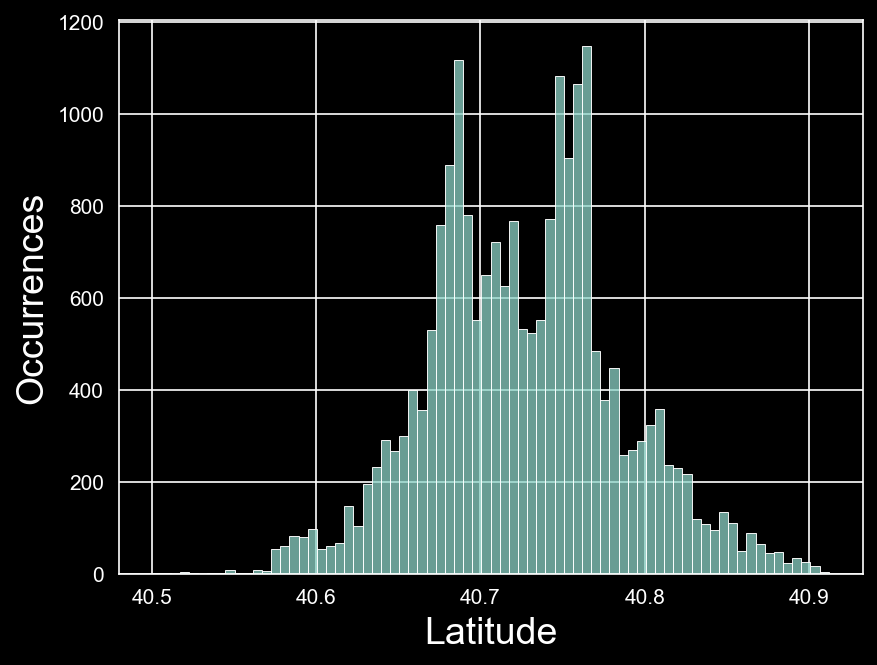

In [24]:
plt.xlabel("Latitude", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['latitude'], bins='auto')

#### Data Cleaning : longitude                            

<Axes: xlabel='Longitude', ylabel='Occurrences'>

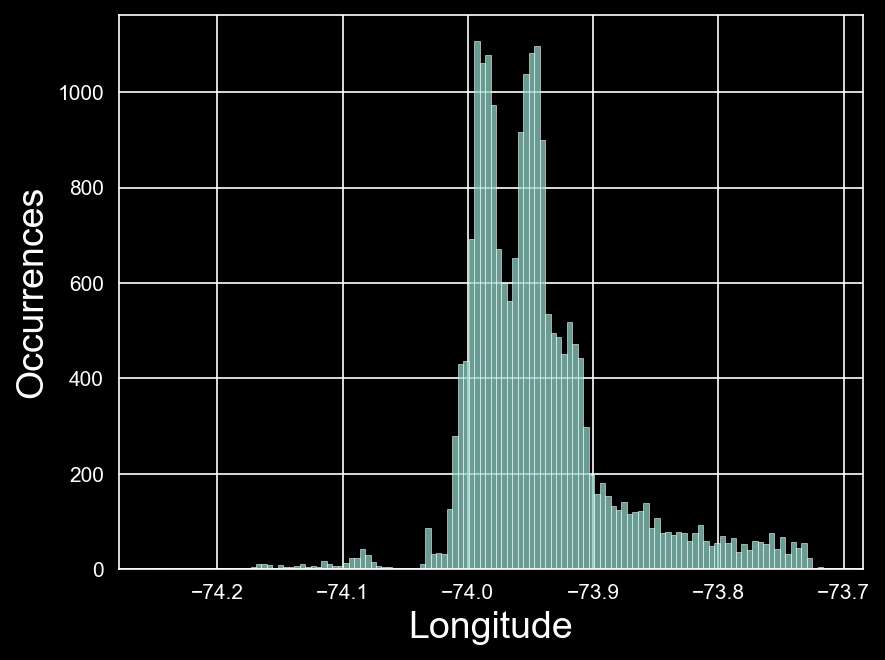

In [25]:
plt.xlabel("Longitude", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['longitude'], bins='auto')

#### Data Cleaning : room_type                            

In [26]:
print(set(ny_listing_raw["room_type"]))

{'Hotel room', 'Shared room', 'Private room', 'Entire home/apt'}


In [27]:
ny_listing_raw['room_type'] = ny_listing_raw['room_type'].astype('category')

<Axes: xlabel='Room Type', ylabel='Count'>

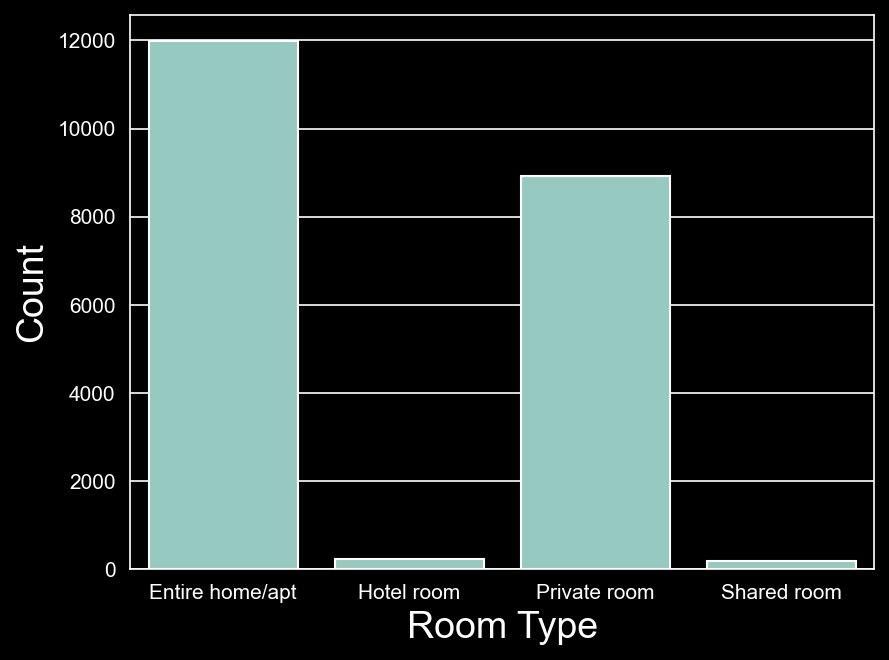

In [28]:
plt.xlabel("Room Type", fontsize=18)
plt.ylabel("Count", fontsize=18)
sns.countplot(data=ny_listing_raw, x="room_type")

#### Data Cleaning : price                                

<Axes: xlabel='Price', ylabel='Occurrences'>

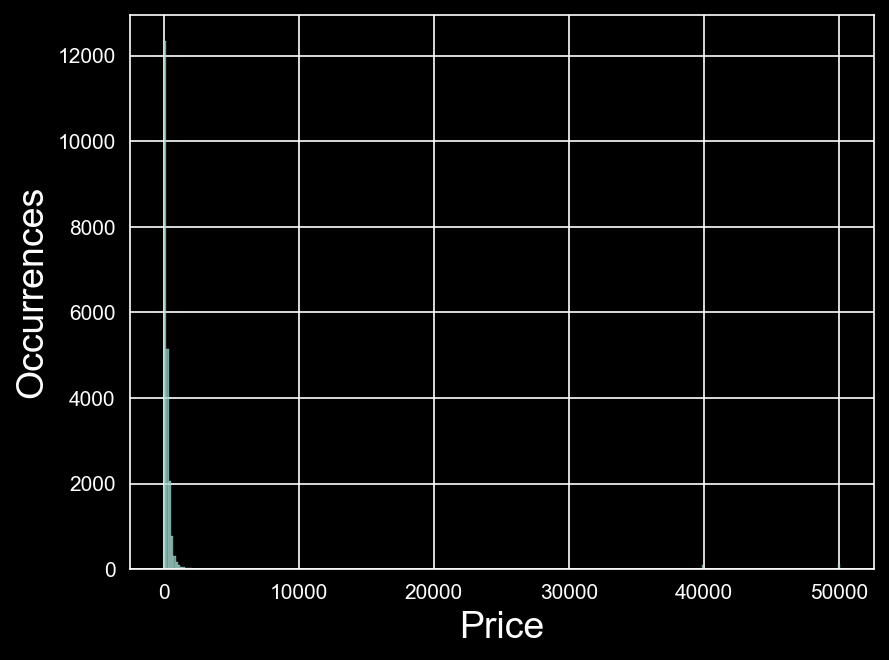

In [29]:
plt.xlabel("Price", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['price'], bins='auto')

In [30]:
high_price_analysis = ny_listing_raw[ny_listing_raw['price'] >2000]
print(high_price_analysis['id'].count())

318


In [31]:
low_price_analysis = ny_listing_raw[ny_listing_raw['price'] < 1]
print(low_price_analysis['price'].count())

0


In [32]:
ny_listing_raw.loc[ny_listing_raw['price'] >2000, 'price'] = pd.NA

<Axes: xlabel='Price', ylabel='Occurrences'>

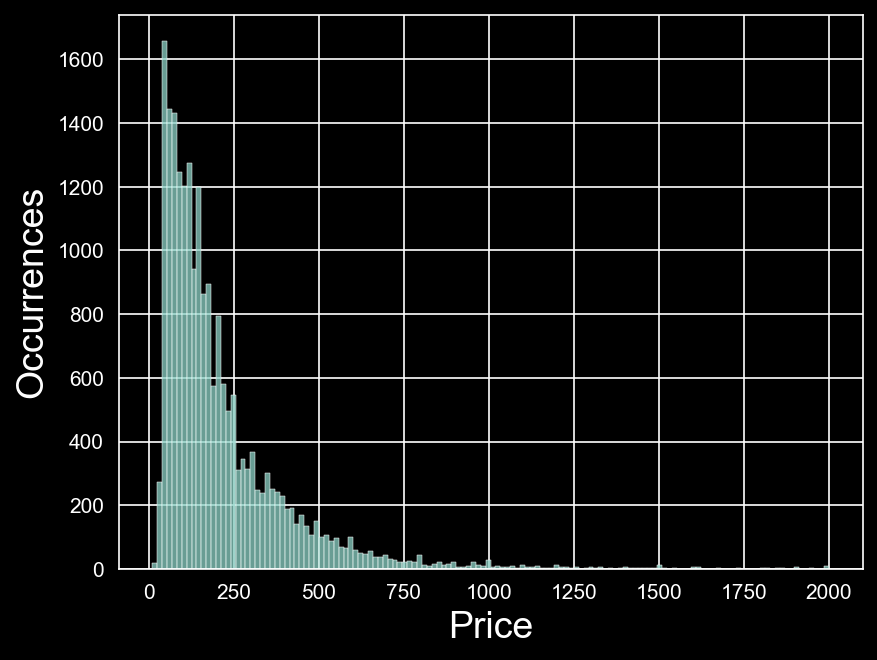

In [33]:
plt.xlabel("Price", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['price'], bins='stone')

In [34]:
ny_listing_raw.loc[ny_listing_raw['price'] >1000, 'price'] = pd.NA

<Axes: xlabel='Price', ylabel='Occurrences'>

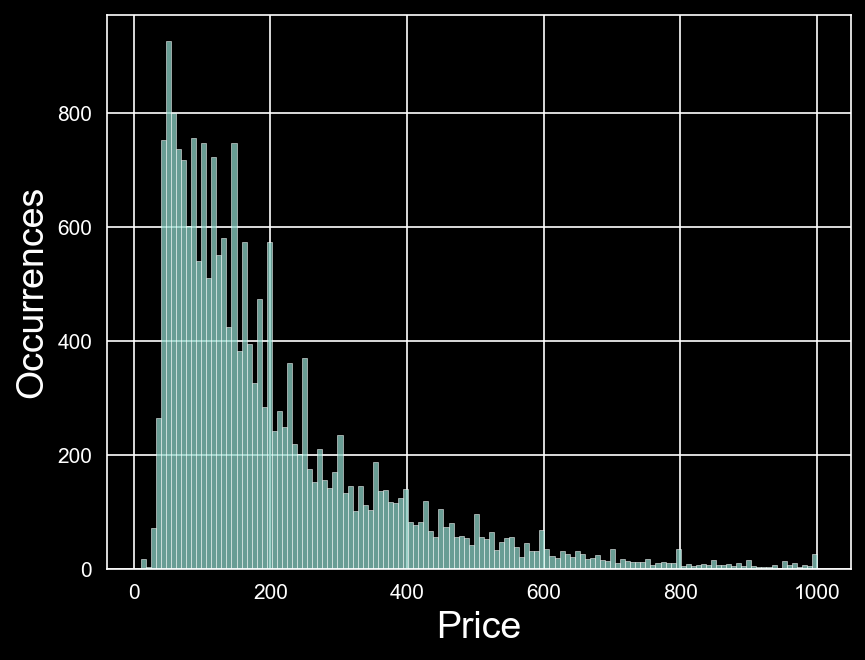

In [35]:
plt.xlabel("Price", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['price'], bins='stone')

#### Data Cleaning : minimum_nights                       

<Axes: xlabel='Minimum Nights', ylabel='Occurrences'>

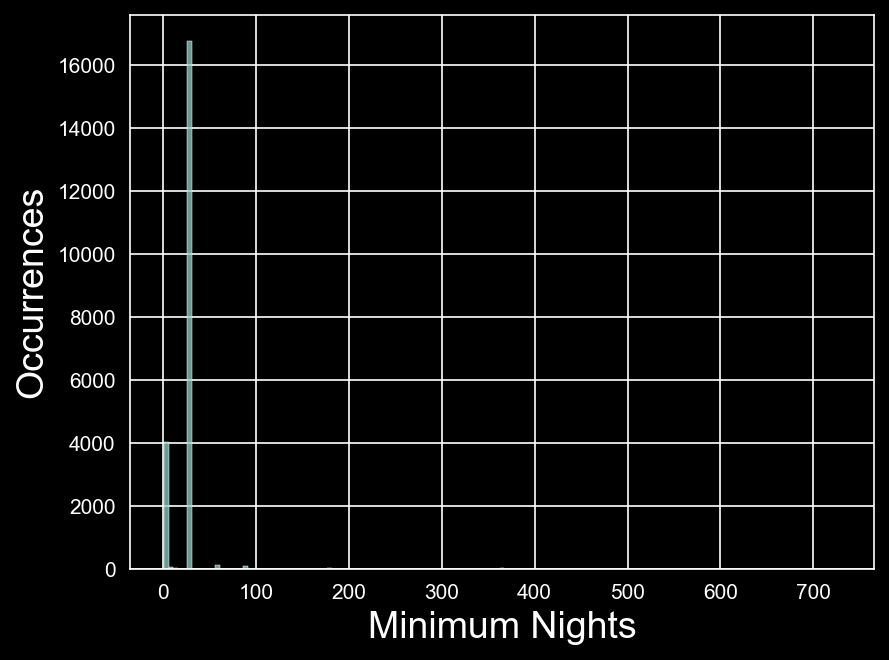

In [36]:
plt.xlabel("Minimum Nights", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['minimum_nights'], bins='stone')

In [37]:
ny_listing_raw.loc[ny_listing_raw['minimum_nights'] >50, 'minimum_nights'] = 50

<Axes: xlabel='Minimum Nights', ylabel='Occurrences'>

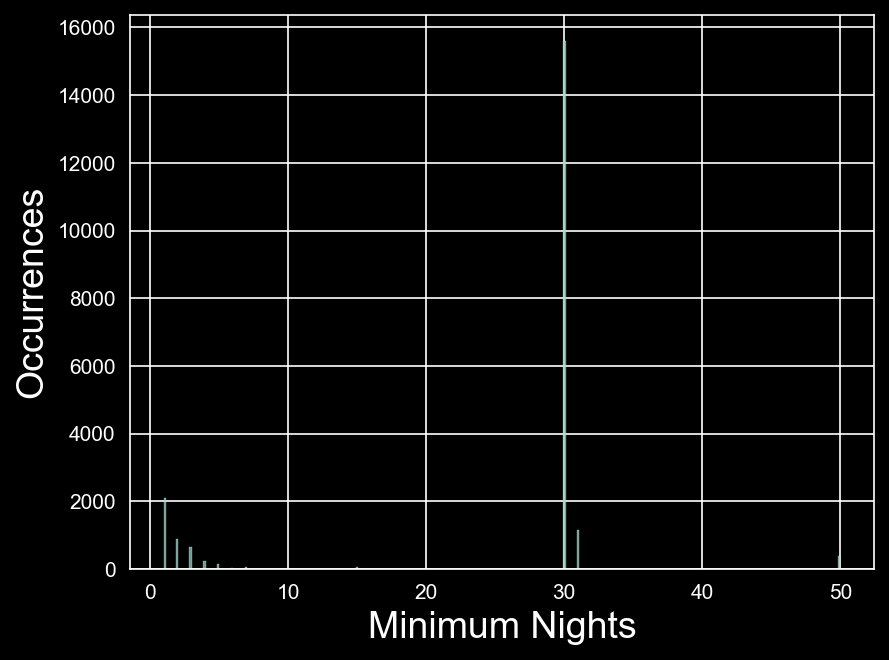

In [38]:
plt.xlabel("Minimum Nights", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['minimum_nights'], bins='auto')

In [39]:
print(sorted(set(ny_listing_raw["minimum_nights"])))

[1, 2, 3, 4, 5, 6, 7, 9, 10, 12, 14, 15, 19, 21, 28, 29, 30, 31, 32, 33, 35, 37, 38, 40, 42, 45, 47, 50]


In [40]:
ny_listing_raw.loc[ny_listing_raw['minimum_nights'] >10, 'minimum_nights'] = (ny_listing_raw['minimum_nights'] // 5) * 5

In [41]:
print(sorted(set(ny_listing_raw["minimum_nights"])))

[1, 2, 3, 4, 5, 6, 7, 9, 10, 15, 20, 25, 30, 35, 40, 45, 50]


<Axes: xlabel='Minimum Nights', ylabel='Count'>

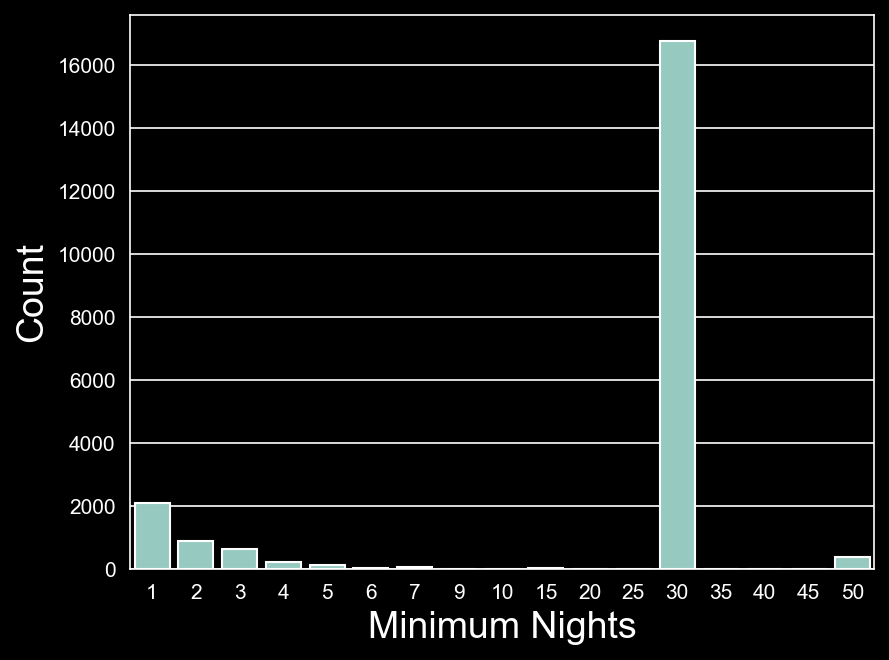

In [42]:
plt.xlabel("Minimum Nights", fontsize=18)
plt.ylabel("Count", fontsize=18)
sns.countplot(data=ny_listing_raw, x="minimum_nights")

In [43]:
ny_listing_raw['minimum_nights'] = ny_listing_raw['minimum_nights'].astype('category')

#### Data Cleaning : number_of_reviews                    

<Axes: xlabel='Number of Reviews', ylabel='Occurrences'>

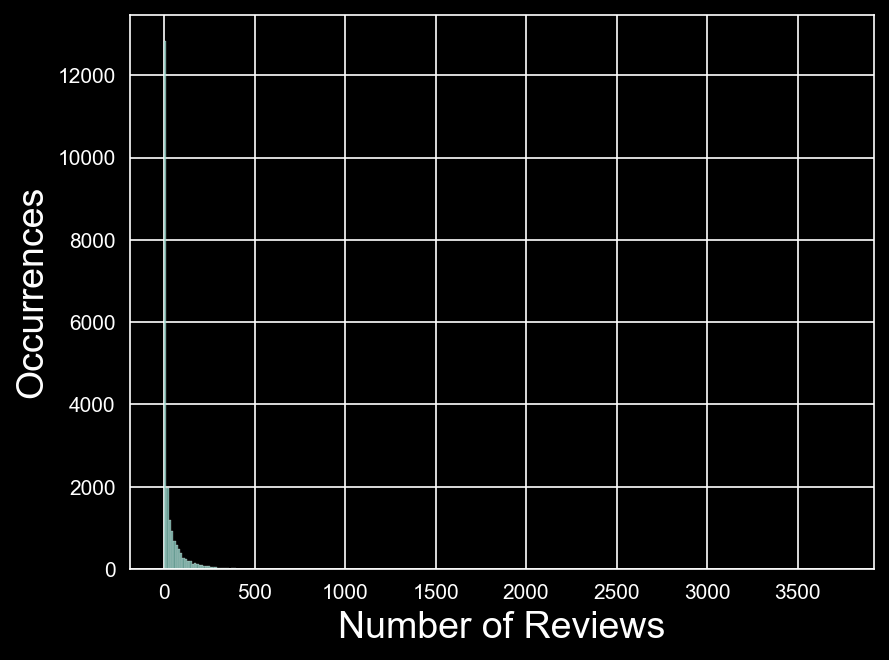

In [44]:
plt.xlabel("Number of Reviews", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['number_of_reviews'], bins='auto')

In [45]:
ny_listing_raw.loc[ny_listing_raw['number_of_reviews'] >100, 'number_of_reviews'] = 100

<Axes: xlabel='Number of Reviews', ylabel='Occurrences'>

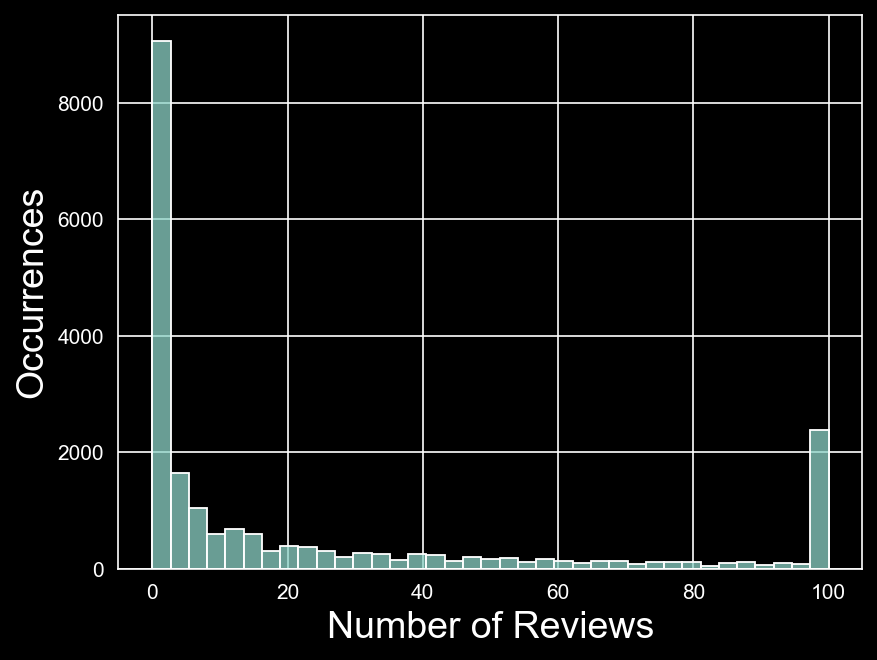

In [46]:
plt.xlabel("Number of Reviews", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['number_of_reviews'], bins='auto')

#### Data Cleaning : last_review                          

In [47]:
format_str = '%Y-%m-%d'
ny_listing_raw['last_review'] = pd.to_datetime(ny_listing_raw['last_review'], format = format_str)

In [48]:
ny_listing_raw['last_review_delta'] = (datetime.now()- ny_listing_raw['last_review']).dt.days

In [49]:
drop_columns.append('last_review')

<Axes: xlabel='Last Review Age', ylabel='Occurrences'>

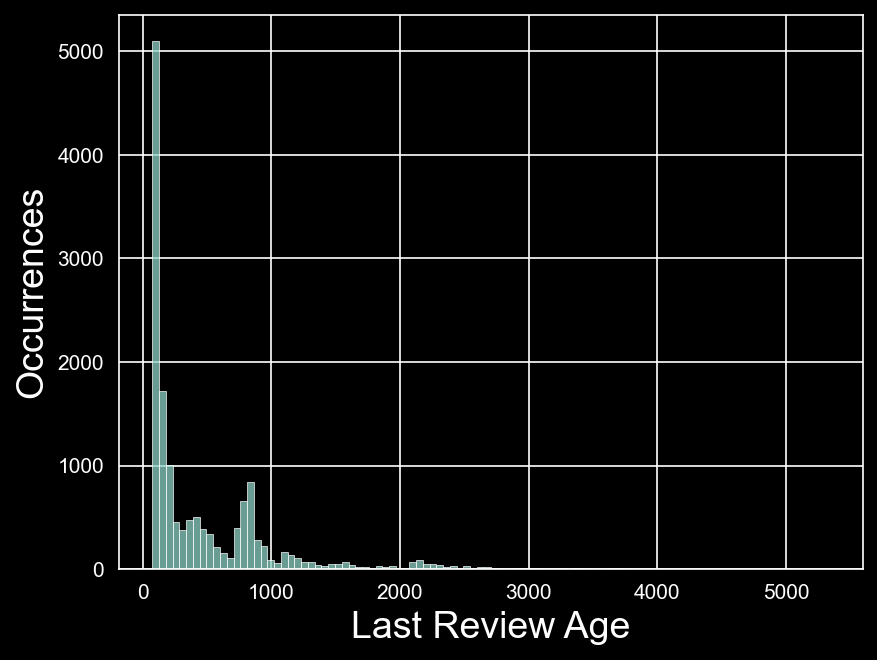

In [50]:
plt.xlabel("Last Review Age", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['last_review_delta'], bins='auto')

In [51]:
ny_listing_raw.loc[ny_listing_raw['last_review_delta'] >3000, 'last_review_delta'] = 3000

<Axes: xlabel='Last Review Age', ylabel='Occurrences'>

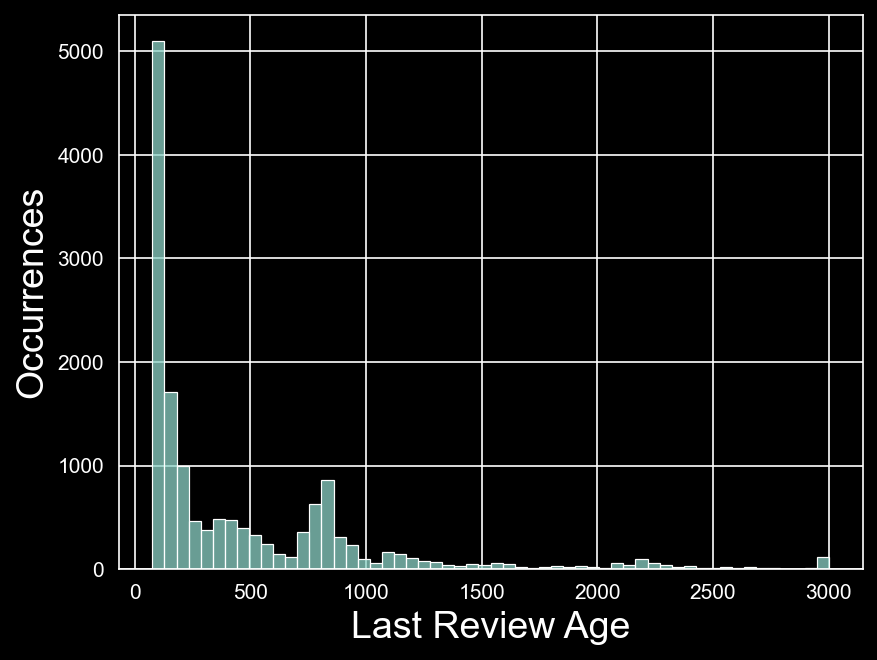

In [52]:
plt.xlabel("Last Review Age", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['last_review_delta'], bins='auto')

#### Data Cleaning : reviews_per_month                    

<Axes: xlabel='Reviews Per Month', ylabel='Occurrences'>

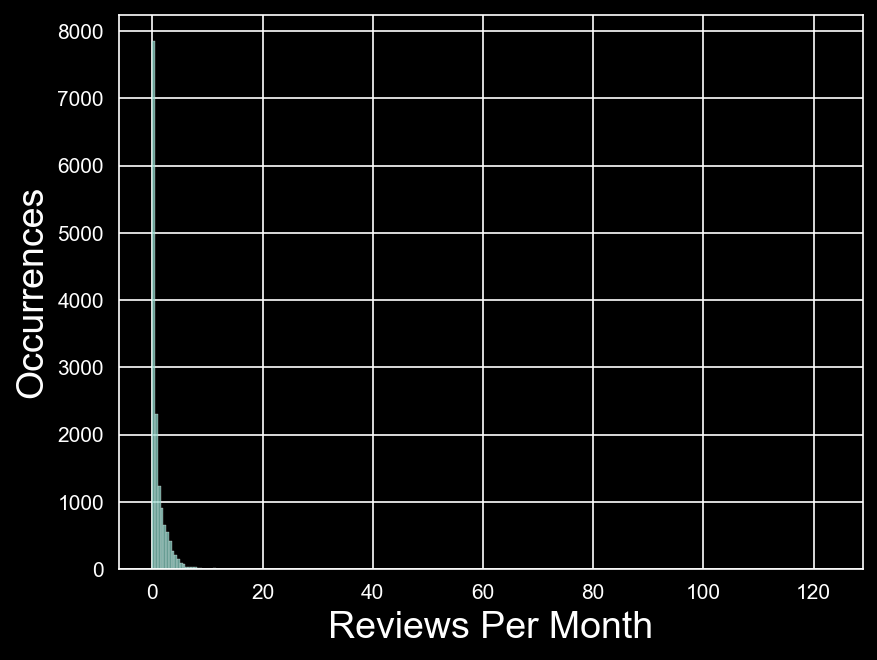

In [53]:
plt.xlabel("Reviews Per Month", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['reviews_per_month'], bins='auto')

In [54]:
reviews_per_month_analysis = ny_listing_raw[ny_listing_raw['reviews_per_month'] >6]
print(reviews_per_month_analysis['id'].count())

244


In [55]:
ny_listing_raw.loc[ny_listing_raw['reviews_per_month'] >6, 'reviews_per_month'] = 6

<Axes: xlabel='Reviews Per Month', ylabel='Occurrences'>

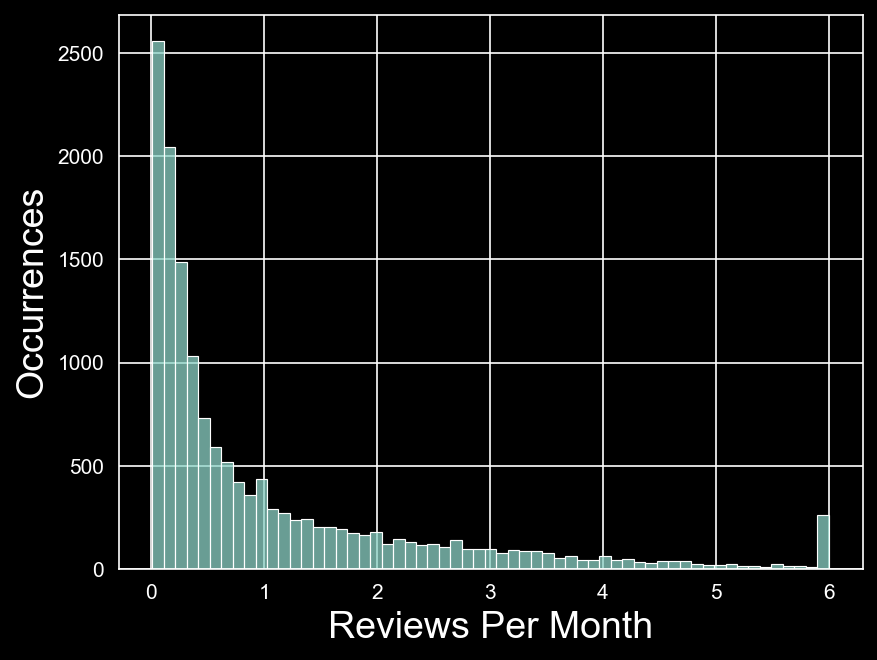

In [56]:
plt.xlabel("Reviews Per Month", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['reviews_per_month'], bins='auto')

In [57]:
ny_listing_raw['reviews_per_month'] = ny_listing_raw['reviews_per_month'].fillna(0) 

#### Data Cleaning : calculated_host_listings_count       

<Axes: xlabel='Calculated Host Listing', ylabel='Occurrences'>

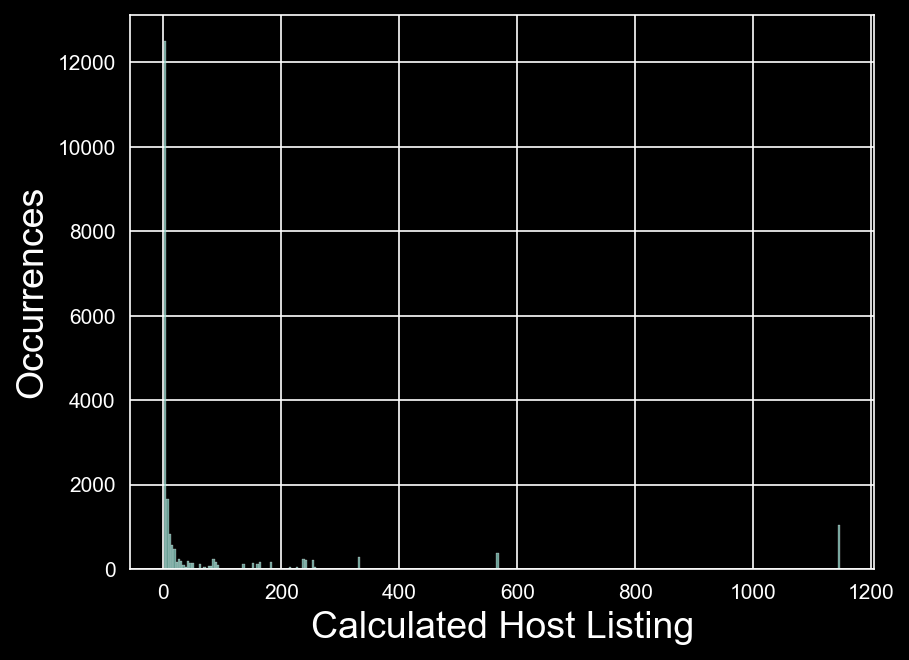

In [58]:
plt.xlabel("Calculated Host Listing", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['calculated_host_listings_count'], bins='auto')

In [59]:
ny_listing_raw.loc[ny_listing_raw['calculated_host_listings_count'] >500, 'calculated_host_listings_count'] = 500
ny_listing_raw.loc[(ny_listing_raw['calculated_host_listings_count'] >100) & (ny_listing_raw['calculated_host_listings_count'] <=500), 'calculated_host_listings_count'] = (ny_listing_raw['calculated_host_listings_count'] // 100) * 100

ny_listing_raw.loc[(ny_listing_raw['calculated_host_listings_count'] >50) & (ny_listing_raw['calculated_host_listings_count'] <=100), 'calculated_host_listings_count'] = (ny_listing_raw['calculated_host_listings_count'] // 25) * 25
ny_listing_raw.loc[(ny_listing_raw['calculated_host_listings_count'] >10) & (ny_listing_raw['calculated_host_listings_count'] <=50), 'calculated_host_listings_count'] = (ny_listing_raw['calculated_host_listings_count'] // 10) * 10

<Axes: xlabel='Calculated Host Listings Count', ylabel='Count'>

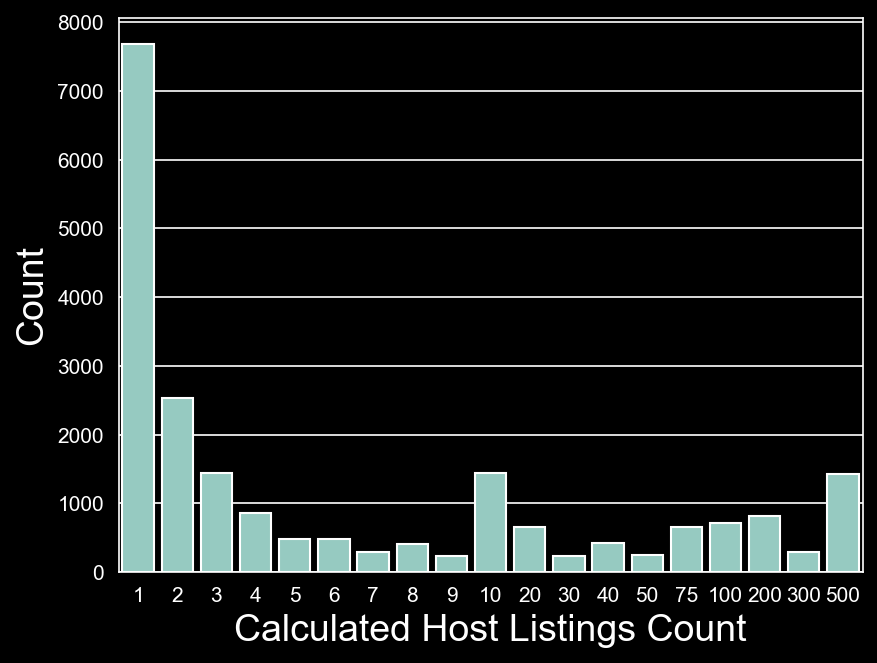

In [60]:
plt.xlabel("Calculated Host Listings Count", fontsize=18)
plt.ylabel("Count", fontsize=18)
sns.countplot(data=ny_listing_raw, x="calculated_host_listings_count")

In [61]:
ny_listing_raw['calculated_host_listings_count'] = ny_listing_raw['calculated_host_listings_count'].astype('category')

#### Data Cleaning : availability_365                     

<Axes: xlabel='Availability Per Year', ylabel='Occurrences'>

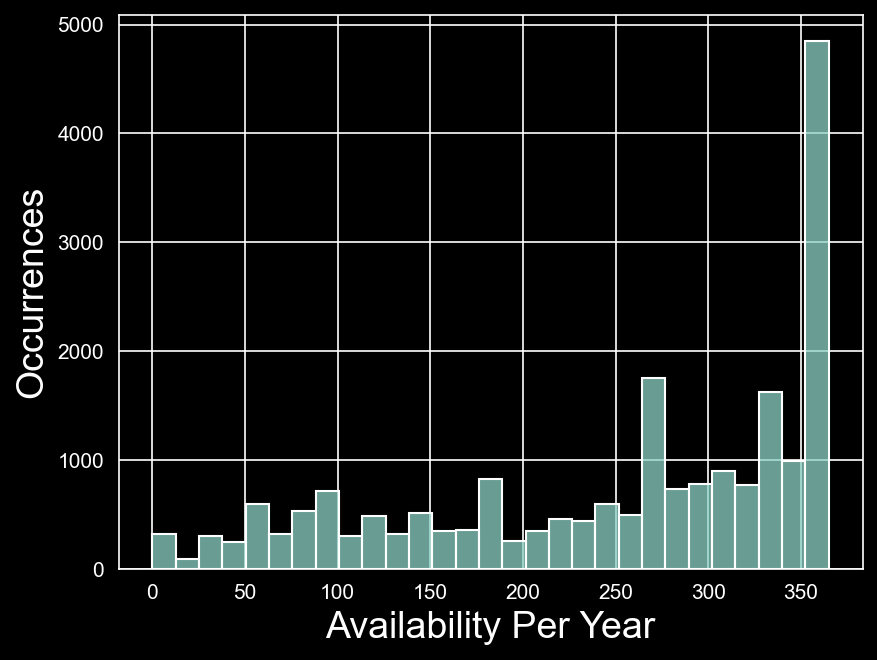

In [62]:
plt.xlabel("Availability Per Year", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['availability_365'], bins='auto')

#### Data Cleaning : number_of_reviews_ltm                

<Axes: xlabel='Number of Reviews', ylabel='Occurrences'>

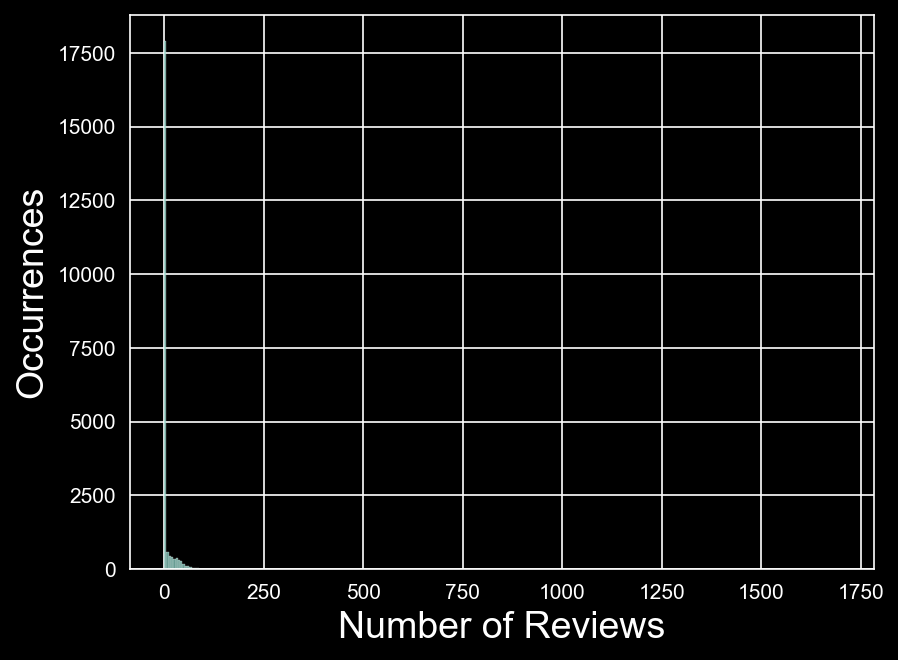

In [63]:
plt.xlabel("Number of Reviews", fontsize=18)
plt.ylabel("Occurrences", fontsize=18)
sns.histplot(ny_listing_raw['number_of_reviews_ltm'], bins='auto')

In [64]:
ny_listing_raw.loc[ny_listing_raw['number_of_reviews_ltm'] >100, 'number_of_reviews_ltm'] = 100
ny_listing_raw.loc[(ny_listing_raw['number_of_reviews_ltm'] >50) & (ny_listing_raw['number_of_reviews_ltm'] <=100), 'number_of_reviews_ltm'] = (ny_listing_raw['number_of_reviews_ltm'] // 25) * 25
ny_listing_raw.loc[(ny_listing_raw['number_of_reviews_ltm'] >10) & (ny_listing_raw['number_of_reviews_ltm'] <=50), 'number_of_reviews_ltm'] = (ny_listing_raw['number_of_reviews_ltm'] // 10) * 10

In [65]:
ny_listing_raw['number_of_reviews_ltm_binned'] = ny_listing_raw['number_of_reviews_ltm'].astype('category')

<Axes: xlabel='Number Of Reviews', ylabel='Count'>

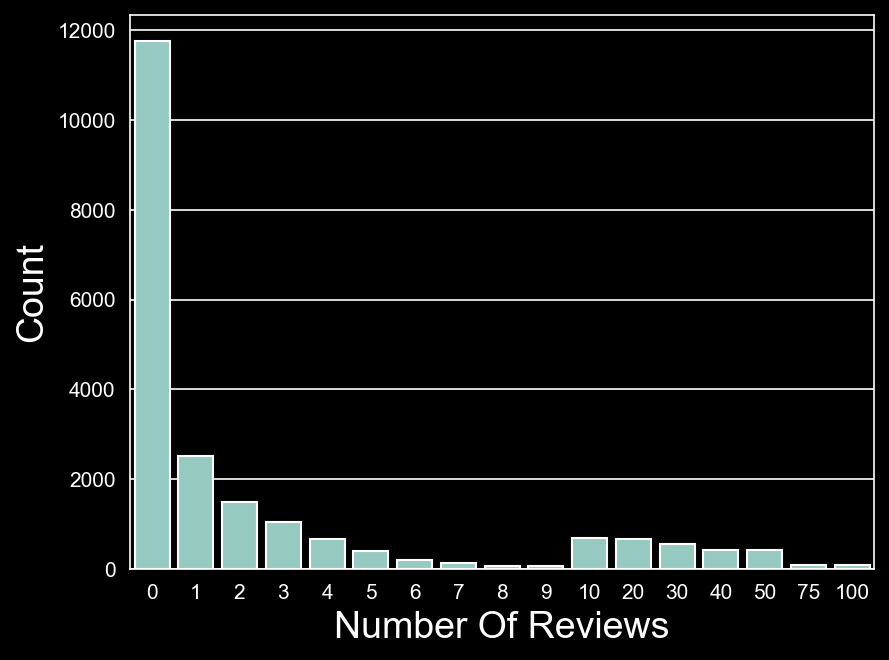

In [66]:
plt.xlabel("Number Of Reviews", fontsize=18)
plt.ylabel("Count", fontsize=18)
sns.countplot(data=ny_listing_raw, x="number_of_reviews_ltm_binned")

In [67]:
drop_columns.append('number_of_reviews_ltm')

#### Data Cleaning : license            

In [68]:
print(set(ny_listing_raw["license"]))

{'OSE-STRREG-0001896', 'OSE-STRREG-0001054', 'OSE-STRREG-0001450', 'OSE-STRREG-0000489', 'OSE-STRREG-0001549', 'OSE-STRREG-0000502', 'OSE-STRREG-0003203', 'OSE-STRREG-0000999', 'OSE-STRREG-0002558', 'OSE-STRREG-0001351', 'OSE-STRREG-0001174', 'OSE-STRREG-0000643', 'OSE-STRREG-0001180', 'OSE-STRREG-0002204', 'OSE-STRREG-0000972', 'OSE-STRREG-0002747', 'OSE-STRREG-0000660', 'OSE-STRREG-0000104', 'OSE-STRREG-0002567', 'OSE-STRREG-0000872', 'OSE-STRREG-0002127', 'OSE-STRREG-0002613', 'OSE-STRREG-0003177', 'OSE-STRREG-0002088', 'OSE-STRREG-0002281', 'OSE-STRREG-0002037', 'OSE-STRREG-0002332', 'OSE-STRREG-0001540', 'OSE-STRREG-0002130', 'OSE-STRREG-0000857', 'OSE-STRREG-0002113', 'OSE-STRREG-0001369', 'OSE-STRREG-0001588', 'OSE-STRREG-0000732', 'OSE-STRREG-0001885', 'OSE-STRREG-0001333', 'OSE-STRREG-0000727', 'OSE-STRREG-0000897', 'OSE-STRREG-0000518', 'OSE-STRREG-0001668', 'OSE-STRREG-0000440', 'OSE-STRREG-0002031', 'OSE-STRREG-0001541', 'OSE-STRREG-0002962', 'OSE-STRREG-0000741', 'OSE-STRR

In [69]:
ny_listing_raw[['license_ose','license_strreg','license_numbers']] = ny_listing_raw['license'].str.split('-',expand=True, n=2)

In [70]:
print(set(ny_listing_raw["license_ose"]))

{nan, 'ose', 'OSE', 'Exempt', 'Ose'}


In [71]:
ny_listing_raw['license_ose'] = ny_listing_raw['license_ose'].str.upper()
ny_listing_raw['license_ose'] = ny_listing_raw['license_ose'].fillna('Unknown') 

In [72]:
print(set(ny_listing_raw["license_ose"]))

{'EXEMPT', 'Unknown', 'OSE'}


In [73]:
ny_listing_raw['license_ose'] = ny_listing_raw['license_ose'].astype('category')

<Axes: xlabel='License Type', ylabel='Count'>

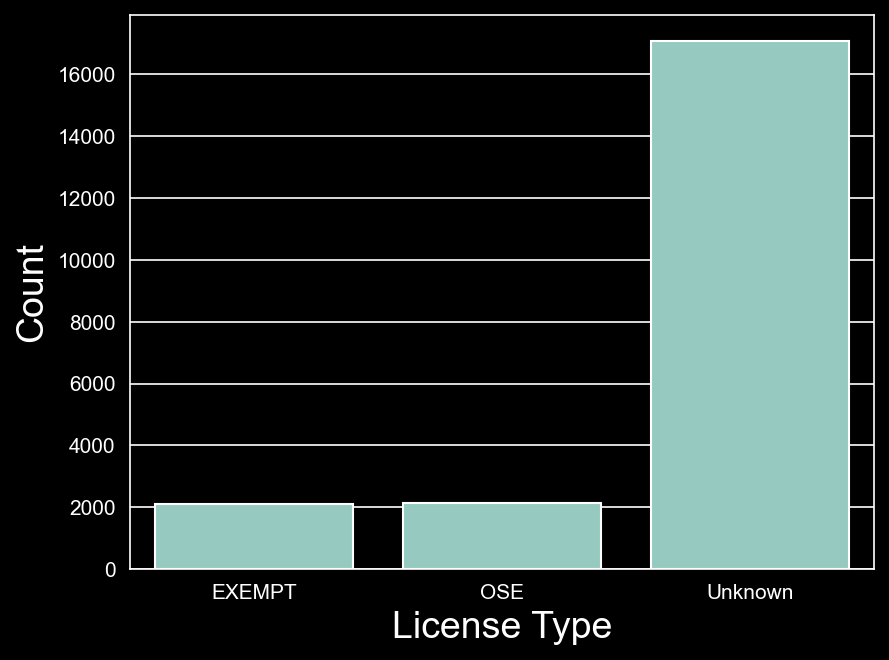

In [74]:
plt.xlabel("License Type", fontsize=18)
plt.ylabel("Count", fontsize=18)
sns.countplot(data=ny_listing_raw, x="license_ose")

In [75]:
drop_columns.append('license')
drop_columns.append('license_strreg')
drop_columns.append('license_numbers')

Drop Columns

In [76]:
ny_listing_raw = ny_listing_raw.drop(columns=drop_columns, axis=1)

In [77]:
ny_listing_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21328 entries, 0 to 36109
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   neighbourhood_group             21328 non-null  category
 1   latitude                        21328 non-null  float64 
 2   longitude                       21328 non-null  float64 
 3   room_type                       21328 non-null  category
 4   price                           20755 non-null  float64 
 5   minimum_nights                  21328 non-null  category
 6   number_of_reviews               21328 non-null  int64   
 7   reviews_per_month               21328 non-null  float64 
 8   calculated_host_listings_count  21328 non-null  category
 9   availability_365                21328 non-null  int64   
 10  neighbourhood_encoded           21328 non-null  float64 
 11  last_review_delta               14944 non-null  float64 
 12  number_of_reviews_ltm_b

In [78]:
ny_listing_clean = ny_listing_raw.dropna()

In [79]:
ny_listing_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14740 entries, 0 to 35918
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   neighbourhood_group             14740 non-null  category
 1   latitude                        14740 non-null  float64 
 2   longitude                       14740 non-null  float64 
 3   room_type                       14740 non-null  category
 4   price                           14740 non-null  float64 
 5   minimum_nights                  14740 non-null  category
 6   number_of_reviews               14740 non-null  int64   
 7   reviews_per_month               14740 non-null  float64 
 8   calculated_host_listings_count  14740 non-null  category
 9   availability_365                14740 non-null  int64   
 10  neighbourhood_encoded           14740 non-null  float64 
 11  last_review_delta               14740 non-null  float64 
 12  number_of_reviews_ltm_b

## Exploratory Data Analysis

#### neighbourhood_group             

<Axes: xlabel='Neighbourhood Group', ylabel='Price'>

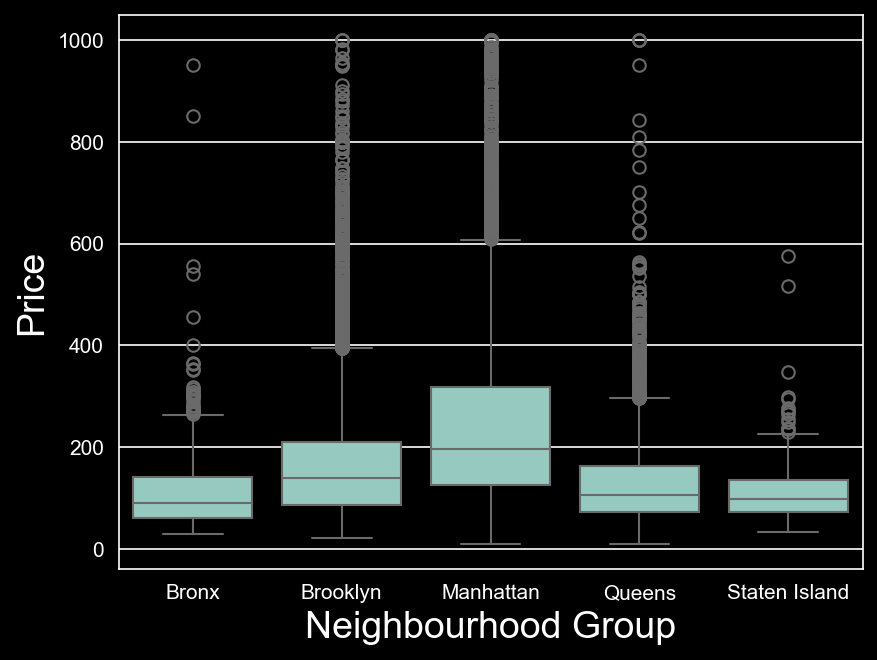

In [80]:
plt.xlabel("Neighbourhood Group", fontsize=18)
plt.ylabel("Price", fontsize=18)
sns.boxplot(data=ny_listing_clean, x="neighbourhood_group", y="price")

In [81]:
category_counts = ny_listing_clean['neighbourhood_group'].value_counts()
print(category_counts)

neighbourhood_group
Manhattan        5802
Brooklyn         5452
Queens           2616
Bronx             626
Staten Island     244
Name: count, dtype: int64


In [82]:
samples_by_group = []
for value in set(ny_listing_clean["neighbourhood_group"]):
    mask = ny_listing_clean["neighbourhood_group"] == value
    samples_by_group.append(ny_listing_clean["price"][mask])

stat, p = stats.kruskal(*samples_by_group)
print(stat)
print(p)

1845.6607645282947
0.0


#### latitude                             

<Axes: xlabel='Latitude', ylabel='Price'>

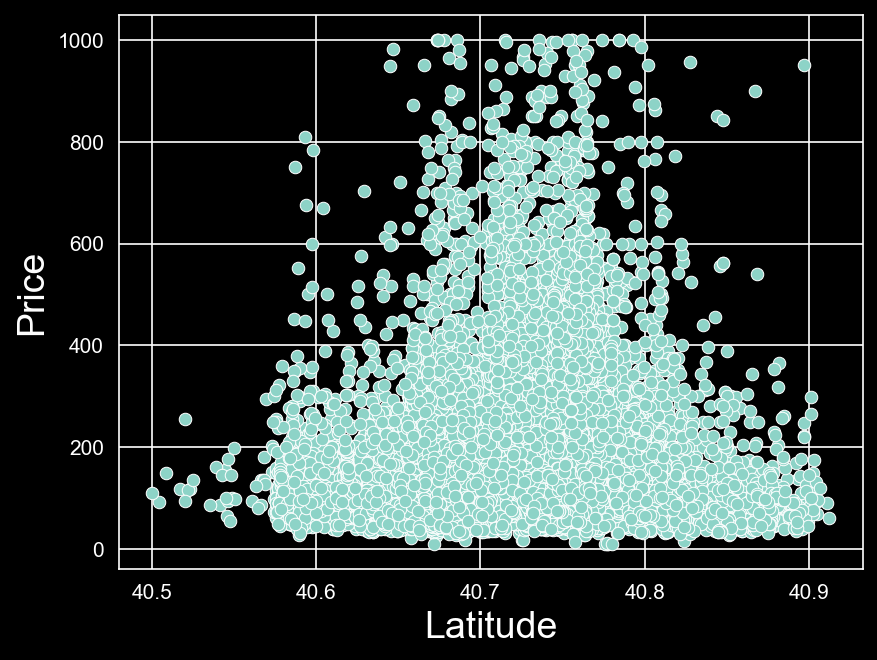

In [83]:
plt.xlabel("Latitude", fontsize=18)
plt.ylabel("Price", fontsize=18)

sns.scatterplot(x="latitude", y="price", data=ny_listing_clean)

In [84]:
slope, intercept, r, p, stderr = stats.linregress(ny_listing_clean["latitude"],ny_listing_clean["price"])
print(f"Pearson's Correlation Coefficient (R): {r}")
print(f"Statistical Significance (P): {p}")

Pearson's Correlation Coefficient (R): 0.04316038593848289
Statistical Significance (P): 1.5881810716619766e-07


####  longitude

<Axes: xlabel='Longitude', ylabel='Price'>

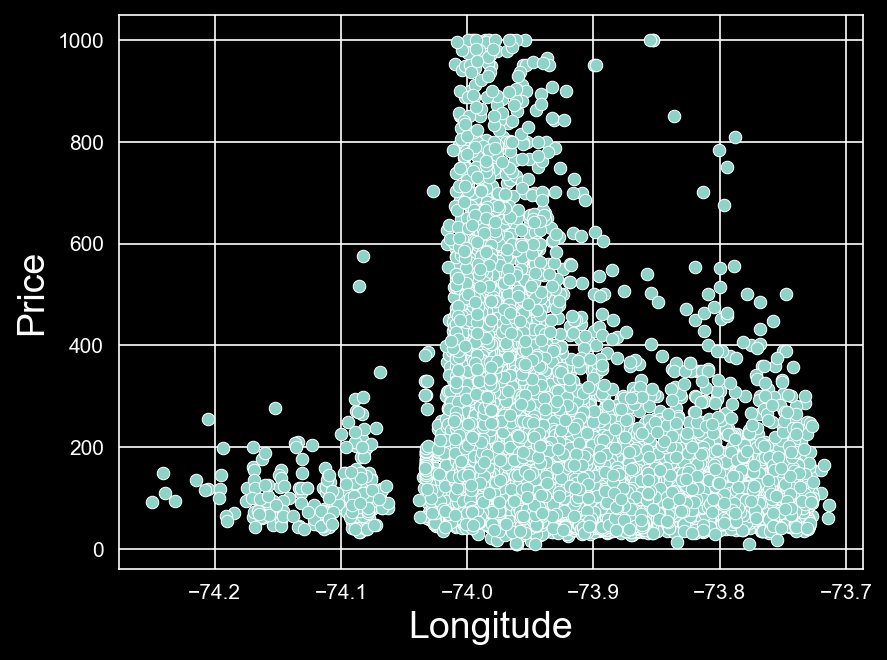

In [85]:
plt.xlabel("Longitude", fontsize=18)
plt.ylabel("Price", fontsize=18)

sns.scatterplot(x="longitude", y="price", data=ny_listing_clean)

In [86]:
slope, intercept, r, p, stderr = stats.linregress(ny_listing_clean["longitude"],ny_listing_clean["price"])
print(f"Pearson's Correlation Coefficient (R): {r}")
print(f"Statistical Significance (P): {p}")

Pearson's Correlation Coefficient (R): -0.24698020556076683
Statistical Significance (P): 1.0000002407569667e-203


#### room_type

<Axes: xlabel='Room Type', ylabel='Price'>

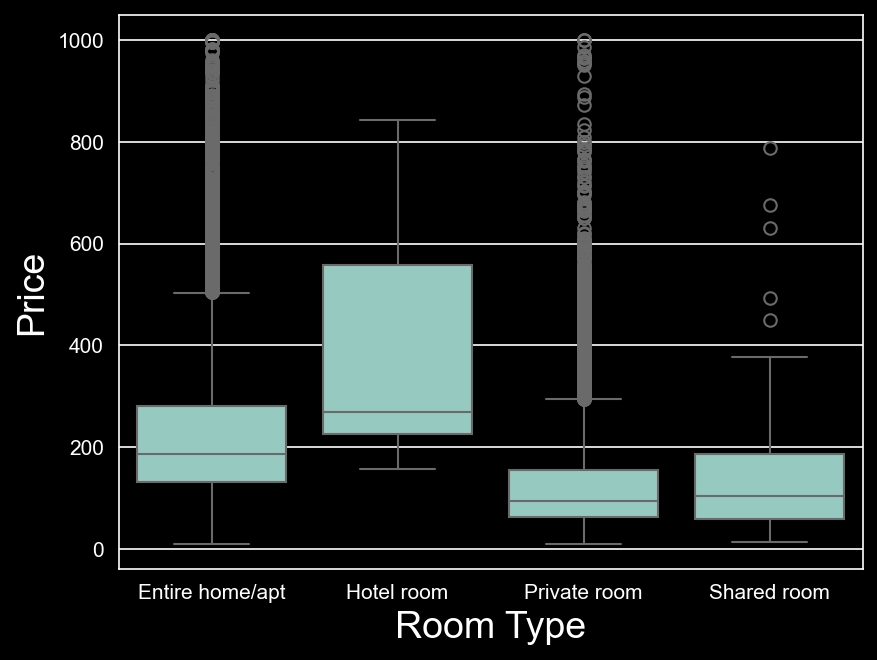

In [87]:
plt.xlabel("Room Type", fontsize=18)
plt.ylabel("Price", fontsize=18)
sns.boxplot(data=ny_listing_clean, x="room_type", y="price")

In [88]:
samples_by_group = []
for value in set(ny_listing_clean["room_type"]):
    mask = ny_listing_clean["room_type"] == value
    samples_by_group.append(ny_listing_clean["price"][mask])

stat, p = stats.kruskal(*samples_by_group)
print(stat)
print(p)

3265.688151123961
0.0


#### minimum_nights

<Axes: xlabel='Minimum Nights Binned', ylabel='Price'>

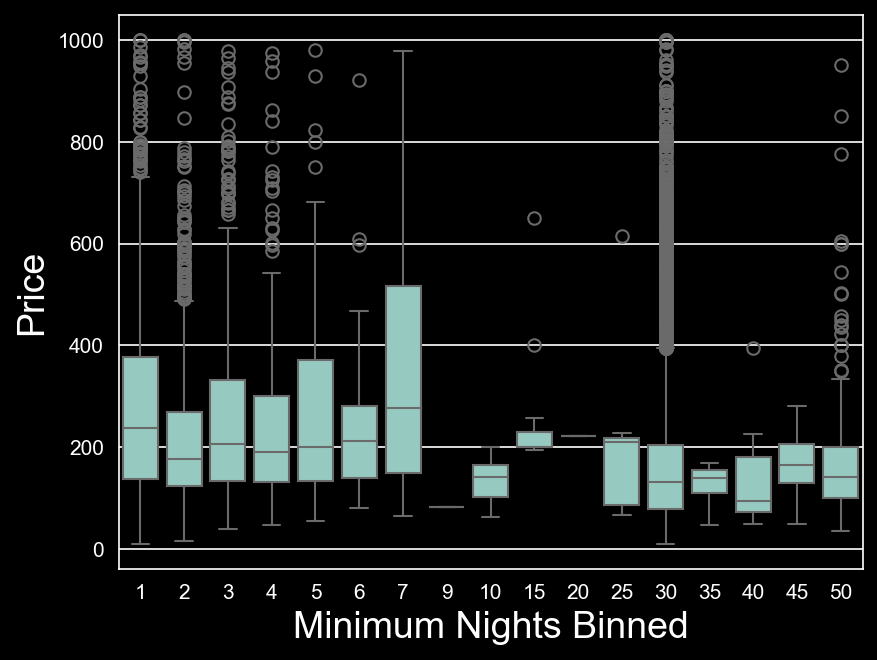

In [89]:
plt.xlabel("Minimum Nights Binned", fontsize=18)
plt.ylabel("Price", fontsize=18)
sns.boxplot(data=ny_listing_clean, x="minimum_nights", y="price")

In [90]:
samples_by_group = []
for value in set(ny_listing_clean["minimum_nights"]):
    mask = ny_listing_clean["minimum_nights"] == value
    samples_by_group.append(ny_listing_clean["price"][mask])

stat, p = stats.kruskal(*samples_by_group)
print(stat)
print(p)

1341.2380714883998
6.9391148910646956e-276


#### number_of_reviews

<Axes: xlabel='Number Of Reviews', ylabel='Price'>

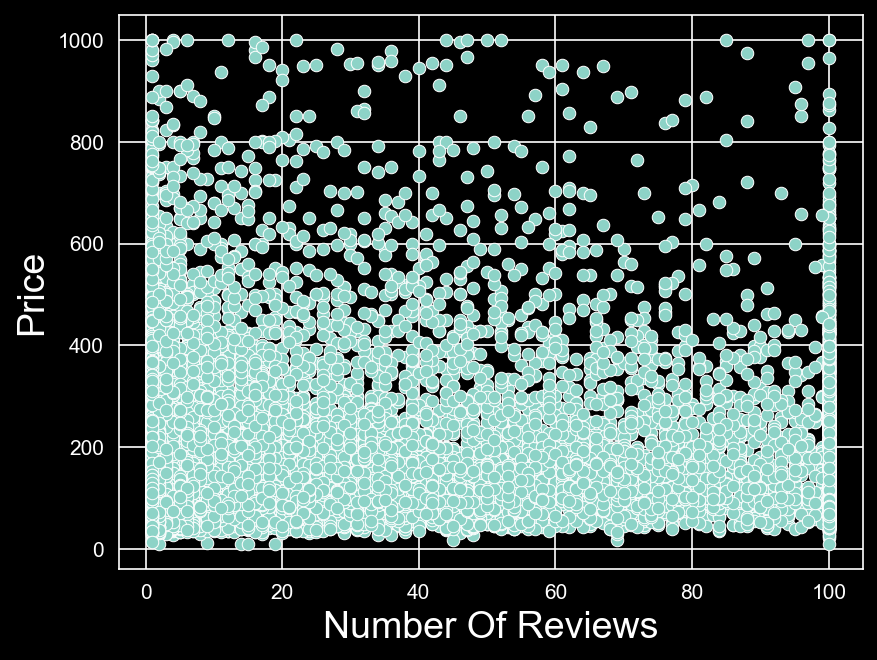

In [91]:
plt.xlabel("Number Of Reviews", fontsize=18)
plt.ylabel("Price", fontsize=18)

sns.scatterplot(x="number_of_reviews", y="price", data=ny_listing_clean)

In [92]:
slope, intercept, r, p, stderr = stats.linregress(ny_listing_clean["number_of_reviews"],ny_listing_clean["price"])
print(f"Pearson's Correlation Coefficient (R): {r}")
print(f"Statistical Significance (P): {p}")

Pearson's Correlation Coefficient (R): 0.024346148879077205
Statistical Significance (P): 0.0031164247932453943


#### reviews_per_month 

<Axes: xlabel='Reviews Per Month', ylabel='Price'>

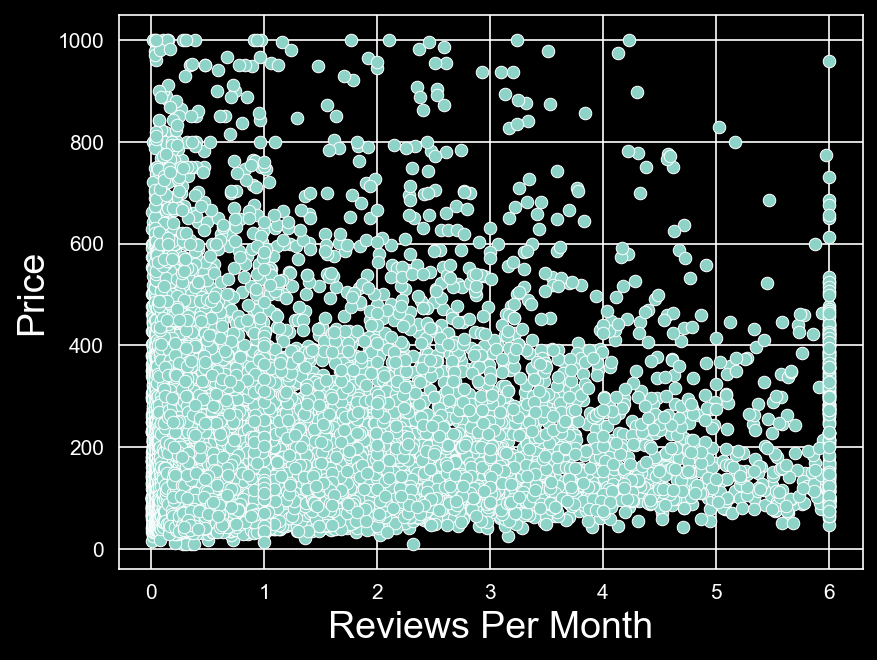

In [93]:
plt.xlabel("Reviews Per Month", fontsize=18)
plt.ylabel("Price", fontsize=18)

sns.scatterplot(x="reviews_per_month", y="price", data=ny_listing_clean)

In [94]:
slope, intercept, r, p, stderr = stats.linregress(ny_listing_clean["neighbourhood_encoded"],ny_listing_clean["price"])
print(f"Pearson's Correlation Coefficient (R): {r}")
print(f"Statistical Significance (P): {p}")

Pearson's Correlation Coefficient (R): 0.31995179074696356
Statistical Significance (P): 0.0


#### calculated_host_listings_count   

<Axes: xlabel='Calculated # of Listings per Host', ylabel='Price'>

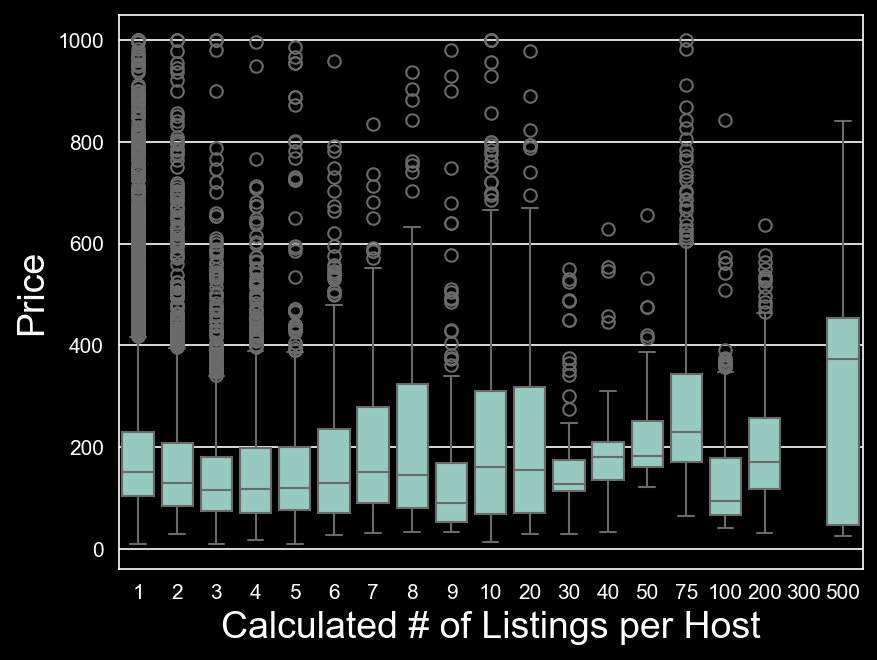

In [95]:
plt.xlabel("Calculated # of Listings per Host", fontsize=18)
plt.ylabel("Price", fontsize=18)
sns.boxplot(data=ny_listing_clean, x="calculated_host_listings_count", y="price")

In [96]:
samples_by_group = []
for value in set(ny_listing_clean["calculated_host_listings_count"]):
    mask = ny_listing_clean["calculated_host_listings_count"] == value
    samples_by_group.append(ny_listing_clean["price"][mask])

stat, p = stats.kruskal(*samples_by_group)
print(stat)
print(p)

716.6458139827648
2.5197896775175875e-141


#### availability_365 

<Axes: xlabel='Availability for the Year', ylabel='Price'>

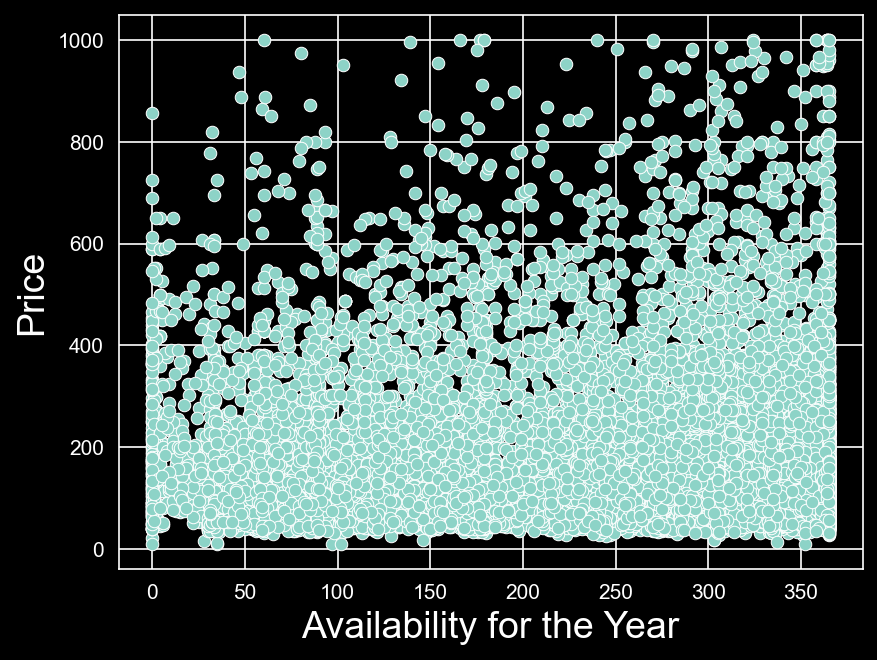

In [97]:
plt.xlabel("Availability for the Year", fontsize=18)
plt.ylabel("Price", fontsize=18)

sns.scatterplot(x="availability_365", y="price", data=ny_listing_clean)

In [98]:
slope, intercept, r, p, stderr = stats.linregress(ny_listing_clean["latitude"],ny_listing_clean["price"])
print(f"Pearson's Correlation Coefficient (R): {r}")
print(f"Statistical Significance (P): {p}")

Pearson's Correlation Coefficient (R): 0.04316038593848289
Statistical Significance (P): 1.5881810716619766e-07


#### neighbourhood_encoded 

<Axes: xlabel='Neighbourhood Encoded', ylabel='Price'>

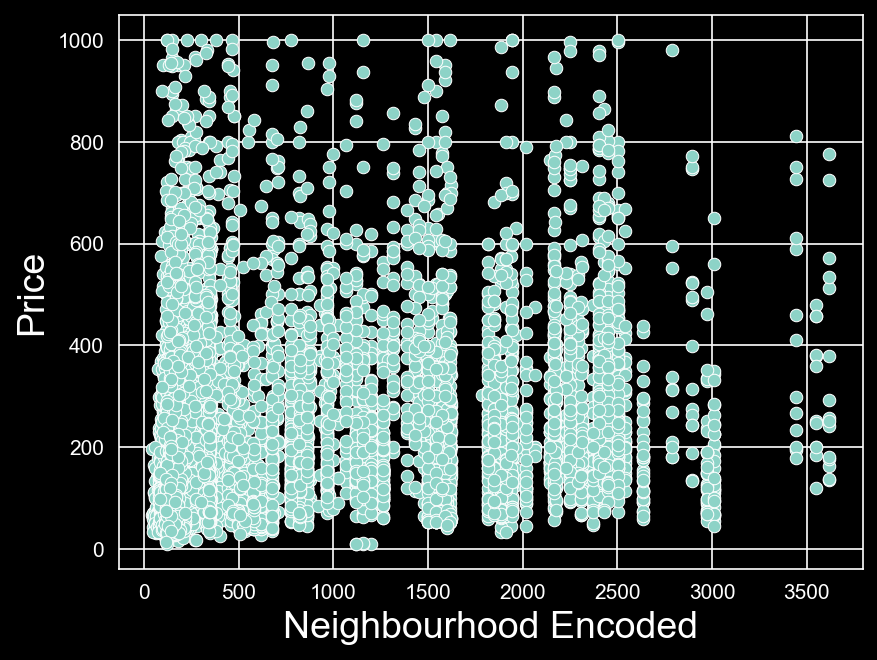

In [99]:
plt.xlabel("Neighbourhood Encoded", fontsize=18)
plt.ylabel("Price", fontsize=18)

sns.scatterplot(x="neighbourhood_encoded", y="price", data=ny_listing_clean)

In [100]:
slope, intercept, r, p, stderr = stats.linregress(ny_listing_clean["neighbourhood_encoded"],ny_listing_clean["price"])

In [101]:
print(f"Pearson's Correlation Coefficient (R): {r}")
print(f"Statistical Significance (P): {p}")

Pearson's Correlation Coefficient (R): 0.31995179074696356
Statistical Significance (P): 0.0


#### last_review_delta 

<Axes: xlabel='Last Review Delta', ylabel='Price'>

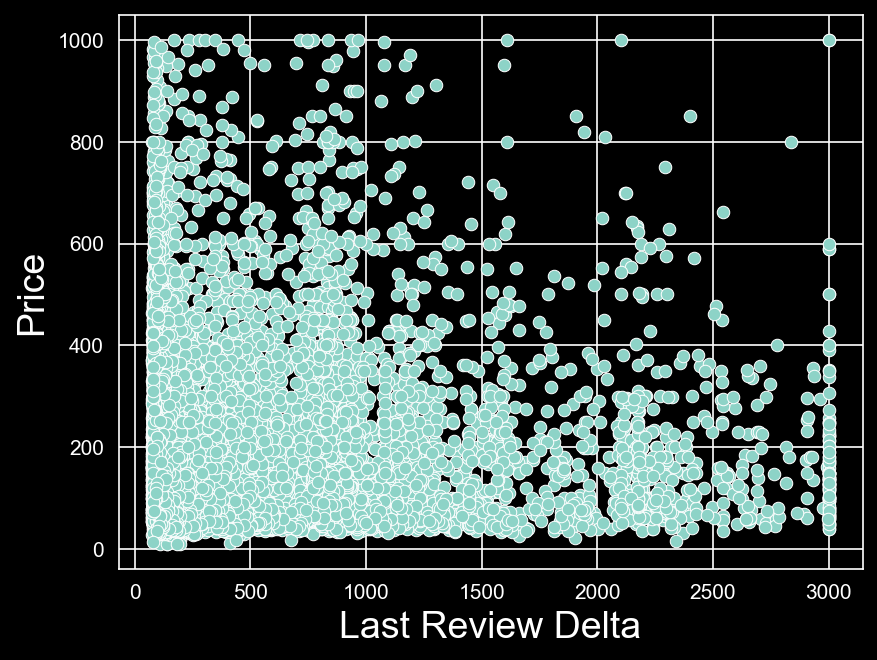

In [102]:
plt.xlabel("Last Review Delta", fontsize=18)
plt.ylabel("Price", fontsize=18)

sns.scatterplot(x="last_review_delta", y="price", data=ny_listing_clean)

In [103]:
slope, intercept, r, p, stderr = stats.linregress(ny_listing_clean["last_review_delta"],ny_listing_clean["price"])

In [104]:
print(f"Pearson's Correlation Coefficient (R): {r}")
print(f"Statistical Significance (P): {p}")

Pearson's Correlation Coefficient (R): -0.003144476043374351
Statistical Significance (P): 0.7026583977484397


#### number_of_reviews_ltm_binned 

<Axes: xlabel='Number of Reviews', ylabel='Price'>

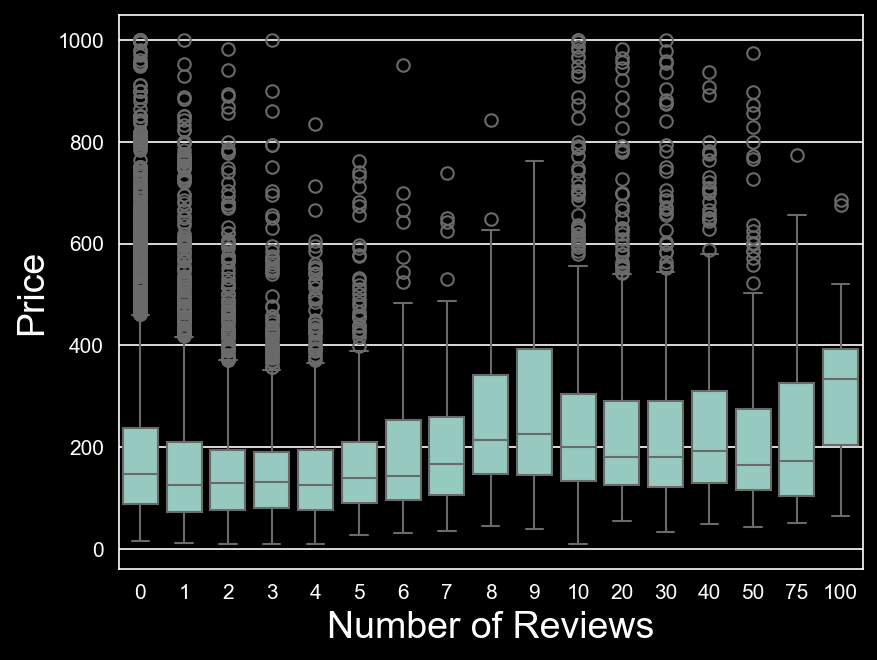

In [105]:
plt.xlabel("Number of Reviews", fontsize=18)
plt.ylabel("Price", fontsize=18)
sns.boxplot(data=ny_listing_clean, x="number_of_reviews_ltm_binned", y="price")

In [106]:
samples_by_group = []
for value in set(ny_listing_clean["number_of_reviews_ltm_binned"]):
    mask = ny_listing_clean["number_of_reviews_ltm_binned"] == value
    samples_by_group.append(ny_listing_clean["price"][mask])

stat, p = stats.kruskal(*samples_by_group)
print(stat)
print(p)

845.5146252467575
1.2197562071101073e-169


#### license_ose

<Axes: xlabel='Has License', ylabel='Price'>

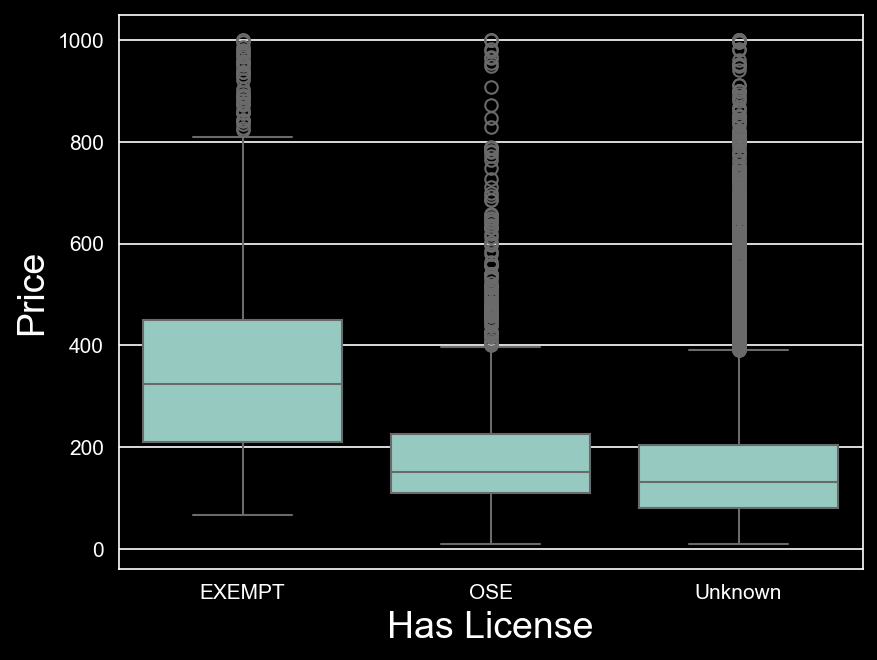

In [107]:
plt.xlabel("Has License", fontsize=18)
plt.ylabel("Price", fontsize=18)
sns.boxplot(data=ny_listing_clean, x="license_ose", y="price")

In [108]:
samples_by_group = []
for value in set(ny_listing_clean["license_ose"]):
    mask = ny_listing_clean["license_ose"] == value
    samples_by_group.append(ny_listing_clean["price"][mask])

stat, p = stats.kruskal(*samples_by_group)
print(stat)
print(p)

2060.7307465585764
0.0


## Baseline Model

In [109]:
ny_listing_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14740 entries, 0 to 35918
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   neighbourhood_group             14740 non-null  category
 1   latitude                        14740 non-null  float64 
 2   longitude                       14740 non-null  float64 
 3   room_type                       14740 non-null  category
 4   price                           14740 non-null  float64 
 5   minimum_nights                  14740 non-null  category
 6   number_of_reviews               14740 non-null  int64   
 7   reviews_per_month               14740 non-null  float64 
 8   calculated_host_listings_count  14740 non-null  category
 9   availability_365                14740 non-null  int64   
 10  neighbourhood_encoded           14740 non-null  float64 
 11  last_review_delta               14740 non-null  float64 
 12  number_of_reviews_ltm_b

In [110]:
labelEncoder = LabelEncoder()

y_listing_data = labelEncoder.fit_transform(ny_listing_clean['price'])
X_listing_data = ny_listing_clean.drop('price', axis = 1)

X_listing_data = pd.get_dummies(X_listing_data,
                                  columns = ['neighbourhood_group', 'room_type','minimum_nights',
                                             'calculated_host_listings_count','number_of_reviews_ltm_binned','license_ose'],
                                             drop_first = True)

X_training, X_testing, y_training, y_testing = train_test_split(
    X_listing_data,
    y_listing_data,
    test_size = 0.2,
    random_state = 24
)

scaler = StandardScaler()
model = LinearRegression()

scaler.fit(X_training)
X_scaled_training = scaler.transform(X_training)

model.fit(X_scaled_training, y_training)

X_scaled_testing = scaler.transform(X_testing)
predictions = model.predict(X_scaled_testing)


In [111]:
mask = np.abs(y_testing) > 1e-5

y_testing_masked = y_testing[mask]
predictions = predictions[mask]

In [112]:
mse = mean_squared_error(y_testing_masked, predictions)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_testing_masked, predictions)
mae = mean_absolute_error(y_testing_masked, predictions)
r2 = r2_score(y_testing_masked, predictions)

print("RMSE:", rmse)
print("MAPE:", mape)
print("MAE:", mae)
print("R^2:", r2)

RMSE: 110.98684382162138
MAPE: 0.6288912272551508
MAE: 74.72404529629607
R^2: 0.4097744722380372


Text(0, 0.5, 'Predicted Values')

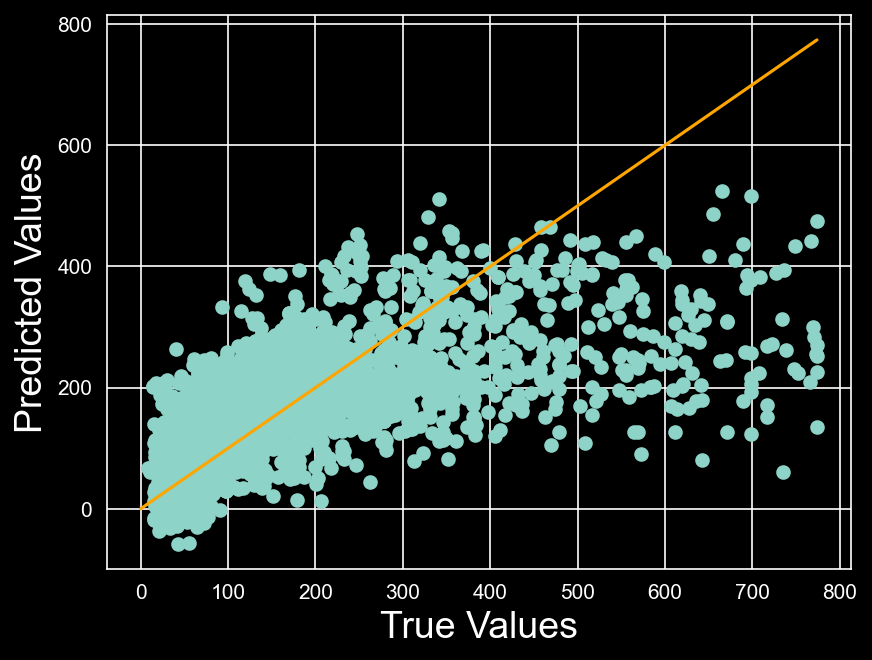

In [113]:
plt.scatter(y_testing_masked, predictions)
plt.plot([0, max(y_testing_masked)], [0, max(y_testing_masked)], color="orange")
plt.xlabel("True Values", fontsize=18)
plt.ylabel("Predicted Values", fontsize=18)

Text(0, 0.5, 'Count')

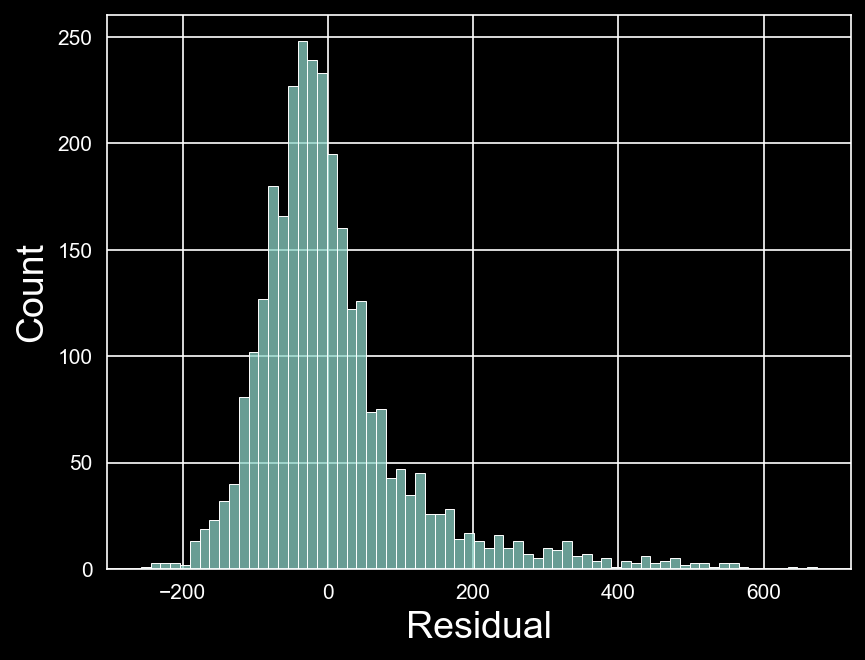

In [114]:
residuals = np.array(y_testing_masked) - np.array(predictions)

sns.histplot(data=residuals)
plt.xlabel("Residual", fontsize=18)
plt.ylabel("Count", fontsize=18)

## Feature Engineering

### Feature Engineering - Normalizing & Polarizing Latitude and Longitude Relative to Geographic Center of NYC

In [115]:
polar_features = ny_listing_clean.copy(True)
# Point Chosen based on approximation by official city definition. This is a more hotly debated topic than expected. Supposedly the "center" in Queens does not have a known origin
long_center = -73.9308684
lat_center = 40.6943464

polar_features['longitude'] = polar_features['longitude'] - long_center
polar_features['latitude'] = polar_features['latitude'] - lat_center
polar_features['polar_radius'] = polar_features['latitude'] ** 2 + polar_features['longitude'] ** 2
polar_features['polar_radius'] = np.sqrt(polar_features['polar_radius'])
polar_features['polar_theta'] = np.arctan2(polar_features['latitude'], polar_features['longitude']) * 180 / np.pi

polar_features.drop('latitude', axis=1, inplace=True)
polar_features.drop('longitude', axis=1, inplace=True)

polar_features.head(10)

,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_encoded,last_review_delta,number_of_reviews_ltm_binned,license_ose,polar_radius,polar_theta
0,Manhattan,Entire home/apt,240.0,30,47,0.24,3,289,2248.128826,1274.0,0,Unknown,0.080627,132.742231
1,Brooklyn,Entire home/apt,96.0,30,100,0.98,1,285,776.504133,190.0,3,Unknown,0.027087,146.364141
2,Manhattan,Private room,59.0,30,1,0.02,2,83,162.614791,1290.0,0,Unknown,0.107361,96.246533
3,Manhattan,Private room,73.0,30,100,1.28,1,186,165.985371,203.0,4,Unknown,0.094918,100.146675
5,Brooklyn,Private room,216.0,2,100,2.21,2,0,197.470498,84.0,30,OSE,0.043089,-176.798514
7,Brooklyn,Entire home/apt,170.0,30,100,0.96,2,275,146.464702,792.0,0,Unknown,0.013141,-131.838951
8,Manhattan,Entire home/apt,175.0,30,58,0.30,1,71,1502.875652,3000.0,0,Unknown,0.091782,127.419953
9,Brooklyn,Private room,90.0,30,82,0.44,6,244,146.943652,260.0,1,Unknown,0.028348,-156.273268
12,Queens,Private room,232.0,2,100,2.45,1,203,2373.924093,81.0,30,OSE,0.055254,105.581327
13,Brooklyn,Entire home/apt,151.0,30,80,0.42,1,286,145.122803,199.0,4,Unknown,0.027651,-147.427223


In [116]:
labelEncoder = LabelEncoder()

y_listing_data = labelEncoder.fit_transform(polar_features['price'])
X_listing_data = polar_features.drop('price', axis = 1)

X_listing_data = pd.get_dummies(X_listing_data,
                                  columns = ['neighbourhood_group',
                                             'room_type',
                                             'minimum_nights',
                                             'calculated_host_listings_count','number_of_reviews_ltm_binned','license_ose'],
                                             drop_first = True)

X_training, X_testing, y_training, y_testing = train_test_split(
    X_listing_data,
    y_listing_data,
    test_size = 0.2,
    random_state = 24
)

scaler = StandardScaler()
model = LinearRegression()

scaler.fit(X_training)
X_scaled_training = scaler.transform(X_training)

model.fit(X_scaled_training, y_training)

X_scaled_testing = scaler.transform(X_testing)
predictions = model.predict(X_scaled_testing)

In [117]:
mask = np.abs(y_testing) > 1e-5

y_testing_masked = y_testing[mask]
predictions = predictions[mask]

In [118]:
mse = mean_squared_error(y_testing_masked, predictions)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_testing_masked, predictions)
mae = mean_absolute_error(y_testing_masked, predictions)
r2 = r2_score(y_testing_masked, predictions)

print("RMSE:", rmse)
print("MAPE:", mape)
print("MAE:", mae)
print("R^2:", r2)

RMSE: 111.47332763208284
MAPE: 0.6356191398176304
MAE: 75.3041371320815
R^2: 0.4045889124471156


Text(0, 0.5, 'Predicted Values')

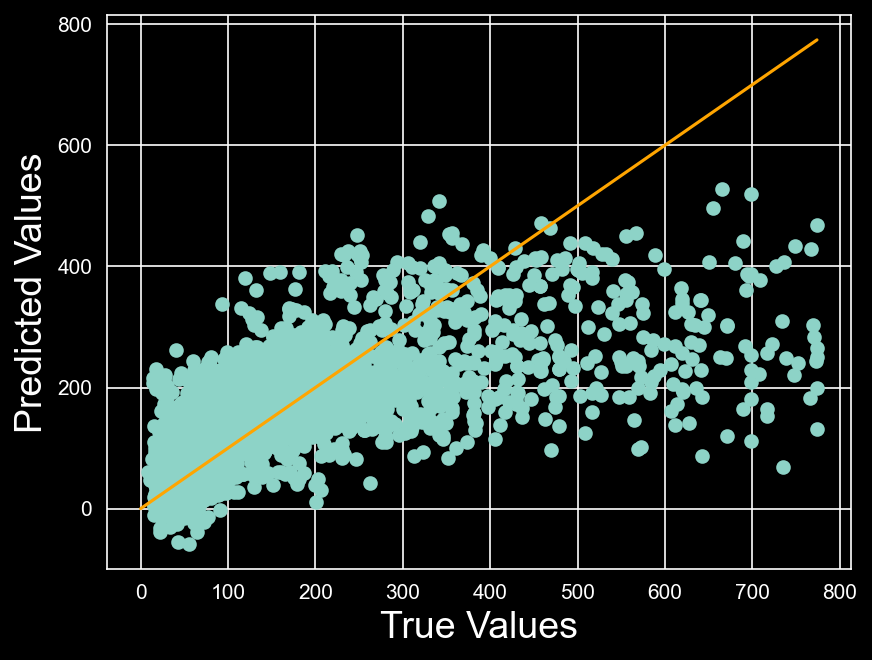

In [119]:
plt.scatter(y_testing_masked, predictions)
plt.plot([0, max(y_testing_masked)], [0, max(y_testing_masked)], color="orange")
plt.xlabel("True Values", fontsize=18)
plt.ylabel("Predicted Values", fontsize=18)

Text(0, 0.5, 'Count')

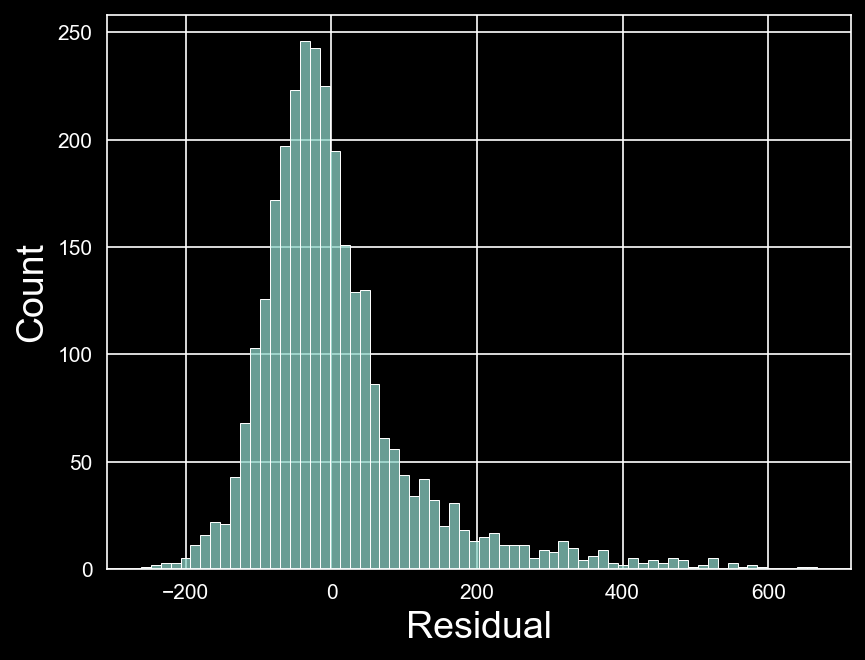

In [120]:
residuals = np.array(y_testing_masked) - np.array(predictions)

sns.histplot(data=residuals)
plt.xlabel("Residual", fontsize=18)
plt.ylabel("Count", fontsize=18)

### Feature Engineering - Normalizing and Polarizing Latitude and Longitude Relative to Neighborhood Centers

In [121]:
neighborhood_polar_features = ny_listing_clean.copy(True)
# Points Chosen based on conversation with native New Yorker
# Concourse
bronx_long_center = -73.922540
bronx_lat_center = 40.831642
# Downtown Brooklyn
brooklyn_long_center = -73.984526
brooklyn_lat_center = 40.696043
# Times Square
manhattan_long_center = -73.985544
manhattan_lat_center = 40.757969
# Flushing
queens_long_center = -73.802958
queens_lat_center = 40.767960
# New Dorp
saten_long_center = -74.116259
saten_lat_center = 40.573970

def polarize_long_per_neighborhood(record):
    match record['neighbourhood_group']:
        case 'Bronx':
            return record['longitude'] - bronx_long_center
        case 'Brooklyn':
            return record['longitude'] - brooklyn_long_center
        case 'Manhattan':
            return record['longitude'] - manhattan_long_center
        case 'Queens':
            return record['longitude'] - queens_long_center
        case 'Saten Island':
            return record['longitude'] - saten_long_center
    return record['longitude']

def polarize_lat_per_neighborhood(record):
    match record['neighbourhood_group']:
        case 'Bronx':
            return record['latitude'] - bronx_lat_center
        case 'Brooklyn':
            return record['latitude'] - brooklyn_lat_center
        case 'Manhattan':
            return record['latitude'] - manhattan_lat_center
        case 'Queens':
            return record['latitude'] - queens_lat_center
        case 'Saten Island':
            return record['latitude'] - saten_lat_center
    return record['latitude']

neighborhood_polar_features['longitude'] = neighborhood_polar_features.apply(polarize_long_per_neighborhood, axis=1)
neighborhood_polar_features['latitude'] = neighborhood_polar_features.apply(polarize_lat_per_neighborhood, axis=1)


neighborhood_polar_features['polar_radius'] = neighborhood_polar_features['latitude'] ** 2 + neighborhood_polar_features['longitude'] ** 2
neighborhood_polar_features['polar_radius'] = np.sqrt(neighborhood_polar_features['polar_radius'])
neighborhood_polar_features['polar_theta'] = np.arctan2(neighborhood_polar_features['latitude'], neighborhood_polar_features['longitude']) * 180 / np.pi

neighborhood_polar_features.drop('latitude', axis=1, inplace=True)
neighborhood_polar_features.drop('longitude', axis=1, inplace=True)

neighborhood_polar_features.head(10)

,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_encoded,last_review_delta,number_of_reviews_ltm_binned,license_ose,polar_radius,polar_theta
0,Manhattan,Entire home/apt,240.0,30,47,0.24,3,289,2248.128826,1274.0,0,Unknown,0.004409,-90.597757
1,Brooklyn,Entire home/apt,96.0,30,100,0.98,1,285,776.504133,190.0,3,Unknown,0.033833,23.161010
2,Manhattan,Private room,59.0,30,1,0.02,2,83,162.614791,1290.0,0,Unknown,0.060878,45.071208
3,Manhattan,Private room,73.0,30,100,1.28,1,186,165.985371,203.0,4,Unknown,0.048262,38.147892
5,Brooklyn,Private room,216.0,2,100,2.21,2,0,197.470498,84.0,30,OSE,0.011400,-21.094885
7,Brooklyn,Entire home/apt,170.0,30,100,0.96,2,275,146.464702,792.0,0,Unknown,0.046338,-14.353160
8,Manhattan,Entire home/apt,175.0,30,58,0.30,1,71,1502.875652,3000.0,0,Unknown,0.009336,96.742106
9,Brooklyn,Private room,90.0,30,82,0.44,6,244,146.943652,260.0,1,Unknown,0.030648,-25.310874
12,Queens,Private room,232.0,2,100,2.45,1,203,2373.924093,81.0,30,OSE,0.144201,-171.871134
13,Brooklyn,Entire home/apt,151.0,30,80,0.42,1,286,145.122803,199.0,4,Unknown,0.034590,-28.647078


In [122]:
labelEncoder = LabelEncoder()

y_listing_data = labelEncoder.fit_transform(neighborhood_polar_features['price'])
X_listing_data = neighborhood_polar_features.drop('price', axis = 1)

X_listing_data = pd.get_dummies(X_listing_data,
                                  columns = ['neighbourhood_group', 'room_type','minimum_nights',
                                             'calculated_host_listings_count','number_of_reviews_ltm_binned','license_ose'],
                                             drop_first = True)

X_training, X_testing, y_training, y_testing = train_test_split(
    X_listing_data,
    y_listing_data,
    test_size = 0.2,
    random_state = 24
)

scaler = StandardScaler()
model = LinearRegression()

scaler.fit(X_training)
X_scaled_training = scaler.transform(X_training)

model.fit(X_scaled_training, y_training)

X_scaled_testing = scaler.transform(X_testing)
predictions = model.predict(X_scaled_testing)

In [123]:
mask = np.abs(y_testing) > 1e-5

y_testing_masked = y_testing[mask]
predictions = predictions[mask]

In [124]:
mse = mean_squared_error(y_testing_masked, predictions)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_testing_masked, predictions)
mae = mean_absolute_error(y_testing_masked, predictions)
r2 = r2_score(y_testing_masked, predictions)

print("RMSE:", rmse)
print("MAPE:", mape)
print("MAE:", mae)
print("R^2:", r2)

RMSE: 110.49256899616626
MAPE: 0.628141908043432
MAE: 74.41069085108444
R^2: 0.4150198508529106


Text(0, 0.5, 'Predicted Values')

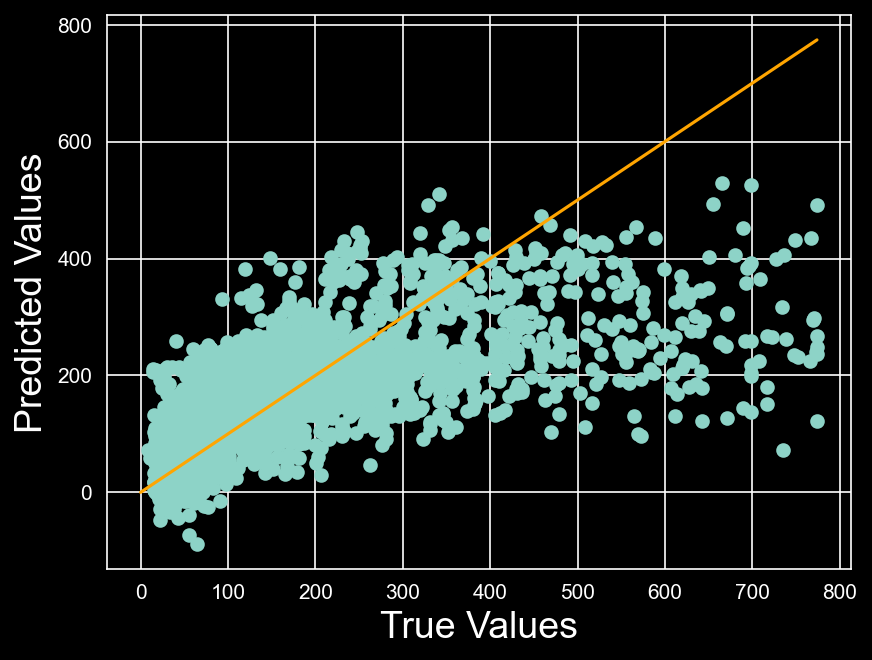

In [125]:
plt.scatter(y_testing_masked, predictions)
plt.plot([0, max(y_testing_masked)], [0, max(y_testing_masked)], color="orange")
plt.xlabel("True Values", fontsize=18)
plt.ylabel("Predicted Values", fontsize=18)

Text(0, 0.5, 'Count')

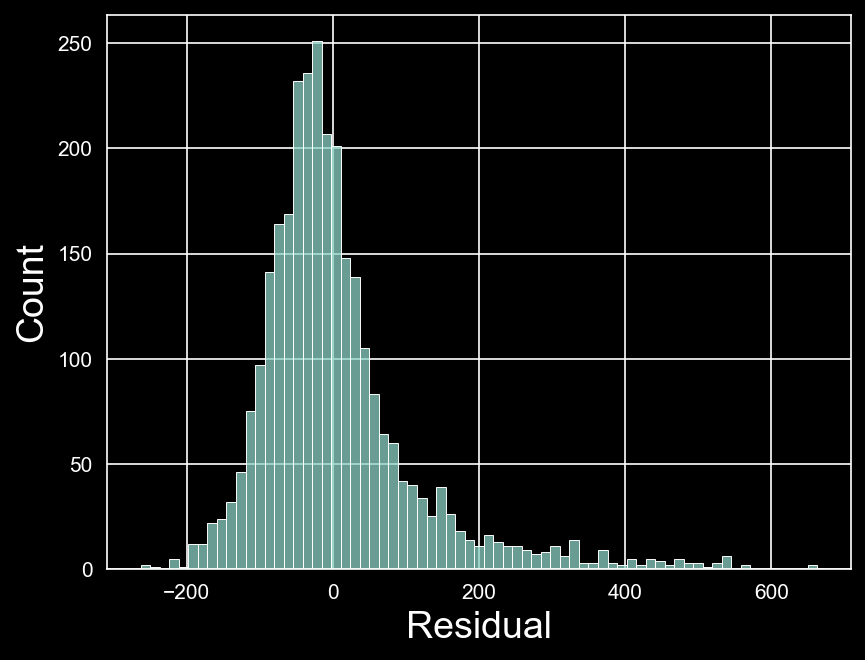

In [126]:
residuals = np.array(y_testing_masked) - np.array(predictions)

sns.histplot(data=residuals)
plt.xlabel("Residual", fontsize=18)
plt.ylabel("Count", fontsize=18)

### Feature Engineering - Calculated Reviews Per Stay

Text(0, 0.5, 'Reviews / Month')

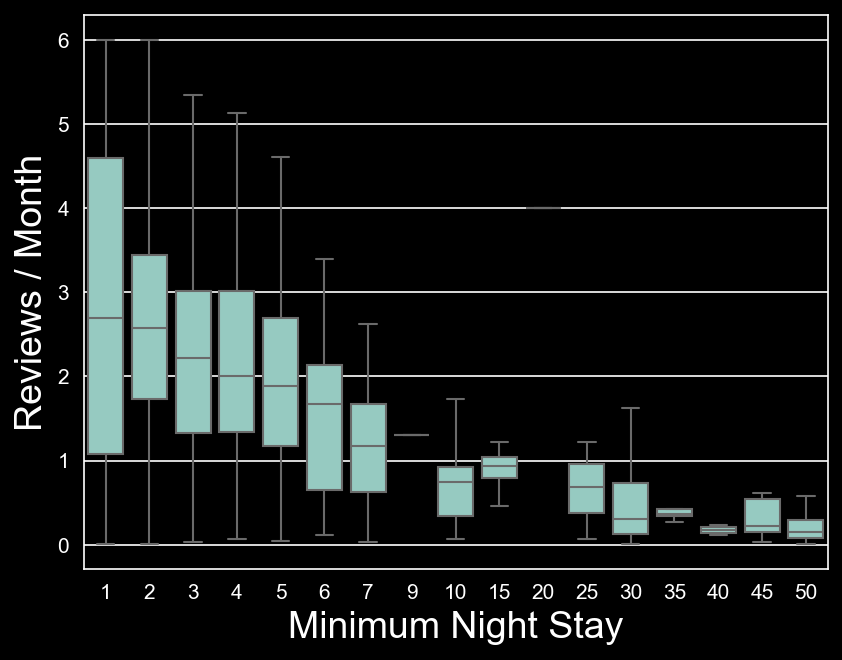

In [127]:
sns.boxplot(ny_listing_clean, x=ny_listing_clean['minimum_nights'], y=ny_listing_clean['reviews_per_month'], showfliers=False)
plt.xlabel("Minimum Night Stay", fontsize=18)
plt.ylabel("Reviews / Month", fontsize=18)

In [128]:
review_per_stay = ny_listing_clean.copy(True)

review_per_stay['minimum_nights'] = pd.to_numeric(review_per_stay['minimum_nights'])
review_per_stay['normalized_reviews_per_stay'] = (review_per_stay['reviews_per_month'] / 30) * (review_per_stay['minimum_nights'])
review_per_stay['minimum_nights'] = review_per_stay['minimum_nights'].astype('category')

review_per_stay.head(10)

,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_encoded,last_review_delta,number_of_reviews_ltm_binned,license_ose,normalized_reviews_per_stay
0,Manhattan,40.753560,-73.985590,Entire home/apt,240.0,30,47,0.24,3,289,2248.128826,1274.0,0,Unknown,0.240000
1,Brooklyn,40.709350,-73.953420,Entire home/apt,96.0,30,100,0.98,1,285,776.504133,190.0,3,Unknown,0.980000
2,Manhattan,40.801070,-73.942550,Private room,59.0,30,1,0.02,2,83,162.614791,1290.0,0,Unknown,0.020000
3,Manhattan,40.787780,-73.947590,Private room,73.0,30,100,1.28,1,186,165.985371,203.0,4,Unknown,1.280000
5,Brooklyn,40.691940,-73.973890,Private room,216.0,2,100,2.21,2,0,197.470498,84.0,30,OSE,0.147333
7,Brooklyn,40.684556,-73.939634,Entire home/apt,170.0,30,100,0.96,2,275,146.464702,792.0,0,Unknown,0.960000
8,Manhattan,40.767240,-73.986640,Entire home/apt,175.0,30,58,0.30,1,71,1502.875652,3000.0,0,Unknown,0.300000
9,Brooklyn,40.682940,-73.956820,Private room,90.0,30,82,0.44,6,244,146.943652,260.0,1,Unknown,0.440000
12,Queens,40.747570,-73.945710,Private room,232.0,2,100,2.45,1,203,2373.924093,81.0,30,OSE,0.163333
13,Brooklyn,40.679460,-73.954170,Entire home/apt,151.0,30,80,0.42,1,286,145.122803,199.0,4,Unknown,0.420000


Text(0, 0.5, 'Reviews / Stay')

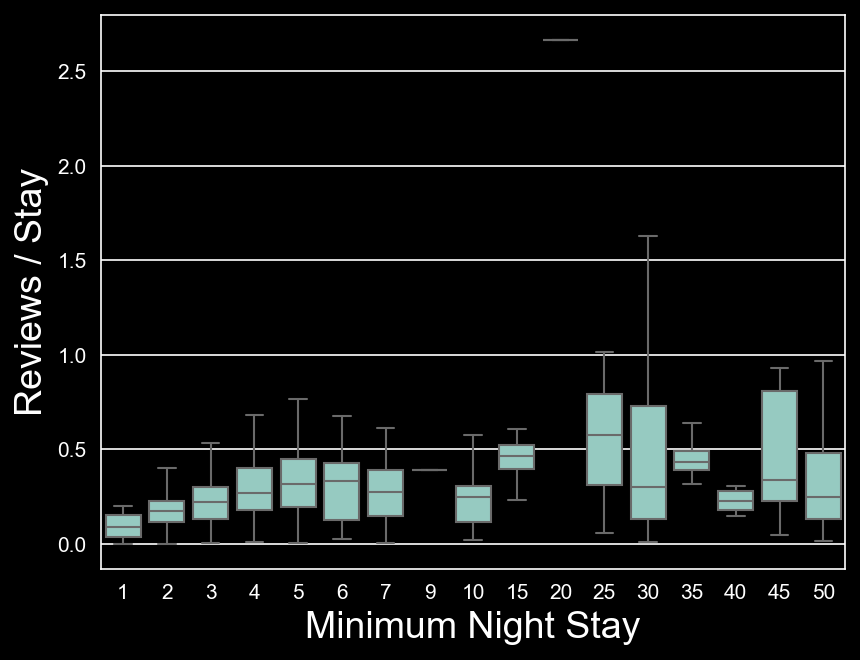

In [129]:
sns.boxplot(review_per_stay, x=review_per_stay['minimum_nights'], y=review_per_stay['normalized_reviews_per_stay'], showfliers=False)
plt.xlabel("Minimum Night Stay", fontsize=18)
plt.ylabel("Reviews / Stay", fontsize=18)

In [130]:
labelEncoder = LabelEncoder()

y_listing_data = labelEncoder.fit_transform(review_per_stay['price'])
X_listing_data = review_per_stay.drop('price', axis = 1)

X_listing_data = pd.get_dummies(X_listing_data,
                                  columns = ['neighbourhood_group',
                                             'room_type','minimum_nights',
                                             'calculated_host_listings_count','number_of_reviews_ltm_binned','license_ose'],
                                             drop_first = True)

X_training, X_testing, y_training, y_testing = train_test_split(
    X_listing_data,
    y_listing_data,
    test_size = 0.2,
    random_state = 24
)

scaler = StandardScaler()
model = LinearRegression()

scaler.fit(X_training)
X_scaled_training = scaler.transform(X_training)

model.fit(X_scaled_training, y_training)

X_scaled_testing = scaler.transform(X_testing)
predictions = model.predict(X_scaled_testing)

In [131]:
mask = np.abs(y_testing) > 1e-5

y_testing_masked = y_testing[mask]
predictions = predictions[mask]

In [132]:
mse = mean_squared_error(y_testing_masked, predictions)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_testing_masked, predictions)
mae = mean_absolute_error(y_testing_masked, predictions)
r2 = r2_score(y_testing_masked, predictions)

print("RMSE:", rmse)
print("MAPE:", mape)
print("MAE:", mae)
print("R^2:", r2)

RMSE: 110.87083177862556
MAPE: 0.6279464119911552
MAE: 74.6120441513205
R^2: 0.41100772620158676


Text(0, 0.5, 'Predicted Values')

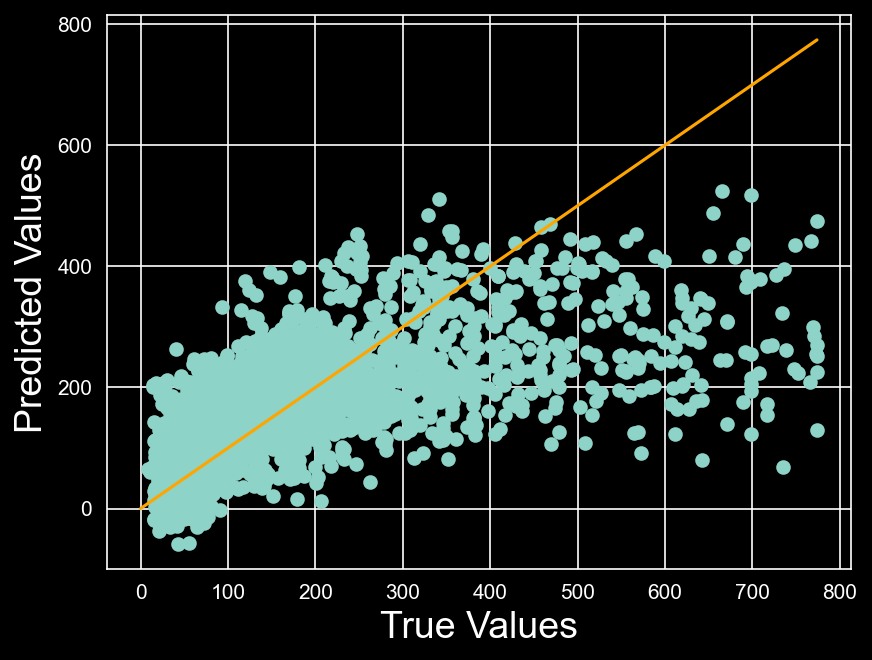

In [133]:
plt.scatter(y_testing_masked, predictions)
plt.plot([0, max(y_testing_masked)], [0, max(y_testing_masked)], color="orange")
plt.xlabel("True Values", fontsize=18)
plt.ylabel("Predicted Values", fontsize=18)

Text(0, 0.5, 'Count')

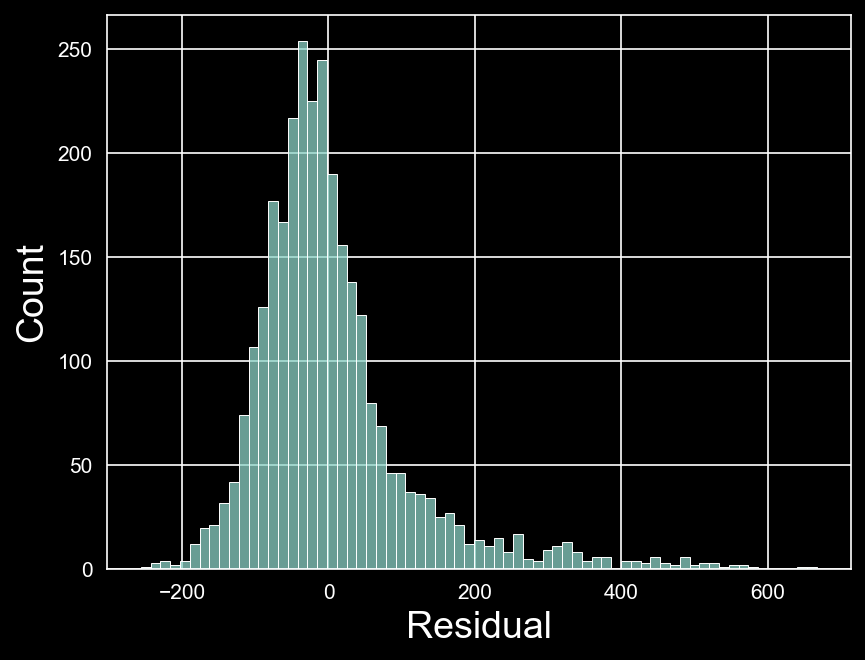

In [134]:
residuals = np.array(y_testing_masked) - np.array(predictions)

sns.histplot(data=residuals)
plt.xlabel("Residual", fontsize=18)
plt.ylabel("Count", fontsize=18)

### Feature Engineering - Combined

In [135]:
engineered_features = ny_listing_clean.copy(True)

engineered_features['longitude'] = engineered_features.apply(polarize_long_per_neighborhood, axis=1)
engineered_features['latitude'] = engineered_features.apply(polarize_lat_per_neighborhood, axis=1)
engineered_features['polar_radius'] = np.sqrt(engineered_features['latitude'] ** 2 + engineered_features['longitude'] ** 2)
engineered_features['polar_theta'] = np.arctan2(engineered_features['latitude'], engineered_features['longitude']) * 180 / np.pi

engineered_features.drop('latitude', axis=1, inplace=True)
engineered_features.drop('longitude', axis=1, inplace=True)

engineered_features['minimum_nights'] = pd.to_numeric(engineered_features['minimum_nights'])
engineered_features['normalized_reviews_per_stay'] = (engineered_features['reviews_per_month'] / 30) * ((365 - engineered_features['availability_365']) / engineered_features['minimum_nights'])
engineered_features['minimum_nights'] = engineered_features['minimum_nights'].astype('category')

engineered_features.head(10)

,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_encoded,last_review_delta,number_of_reviews_ltm_binned,license_ose,polar_radius,polar_theta,normalized_reviews_per_stay
0,Manhattan,Entire home/apt,240.0,30,47,0.24,3,289,2248.128826,1274.0,0,Unknown,0.004409,-90.597757,0.020267
1,Brooklyn,Entire home/apt,96.0,30,100,0.98,1,285,776.504133,190.0,3,Unknown,0.033833,23.161010,0.087111
2,Manhattan,Private room,59.0,30,1,0.02,2,83,162.614791,1290.0,0,Unknown,0.060878,45.071208,0.006267
3,Manhattan,Private room,73.0,30,100,1.28,1,186,165.985371,203.0,4,Unknown,0.048262,38.147892,0.254578
5,Brooklyn,Private room,216.0,2,100,2.21,2,0,197.470498,84.0,30,OSE,0.011400,-21.094885,13.444167
7,Brooklyn,Entire home/apt,170.0,30,100,0.96,2,275,146.464702,792.0,0,Unknown,0.046338,-14.353160,0.096000
8,Manhattan,Entire home/apt,175.0,30,58,0.30,1,71,1502.875652,3000.0,0,Unknown,0.009336,96.742106,0.098000
9,Brooklyn,Private room,90.0,30,82,0.44,6,244,146.943652,260.0,1,Unknown,0.030648,-25.310874,0.059156
12,Queens,Private room,232.0,2,100,2.45,1,203,2373.924093,81.0,30,OSE,0.144201,-171.871134,6.615000
13,Brooklyn,Entire home/apt,151.0,30,80,0.42,1,286,145.122803,199.0,4,Unknown,0.034590,-28.647078,0.036867


In [136]:
labelEncoder = LabelEncoder()

y_listing_data = labelEncoder.fit_transform(engineered_features['price'])
X_listing_data = engineered_features.drop('price', axis = 1)

X_listing_data = pd.get_dummies(X_listing_data,
                                  columns = ['neighbourhood_group',
                                             'room_type','minimum_nights',
                                             'calculated_host_listings_count','number_of_reviews_ltm_binned','license_ose'],
                                             drop_first = True)

X_training, X_testing, y_training, y_testing = train_test_split(
    X_listing_data,
    y_listing_data,
    test_size = 0.2,
    random_state = 24
)

scaler = StandardScaler()
model = LinearRegression()

scaler.fit(X_training)
X_scaled_training = scaler.transform(X_training)

model.fit(X_scaled_training, y_training)

X_scaled_testing = scaler.transform(X_testing)
predictions = model.predict(X_scaled_testing)

In [137]:
mask = np.abs(y_testing) > 1e-5

y_testing_masked = y_testing[mask]
predictions = predictions[mask]

In [138]:
mse = mean_squared_error(y_testing_masked, predictions)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_testing_masked, predictions)
mae = mean_absolute_error(y_testing_masked, predictions)
r2 = r2_score(y_testing_masked, predictions)

print("RMSE:", rmse)
print("MAPE:", mape)
print("MAE:", mae)
print("R^2:", r2)

RMSE: 110.4728174852102
MAPE: 0.6278171255413872
MAE: 74.39476084672727
R^2: 0.41522897277340054


Text(0, 0.5, 'Predicted Values')

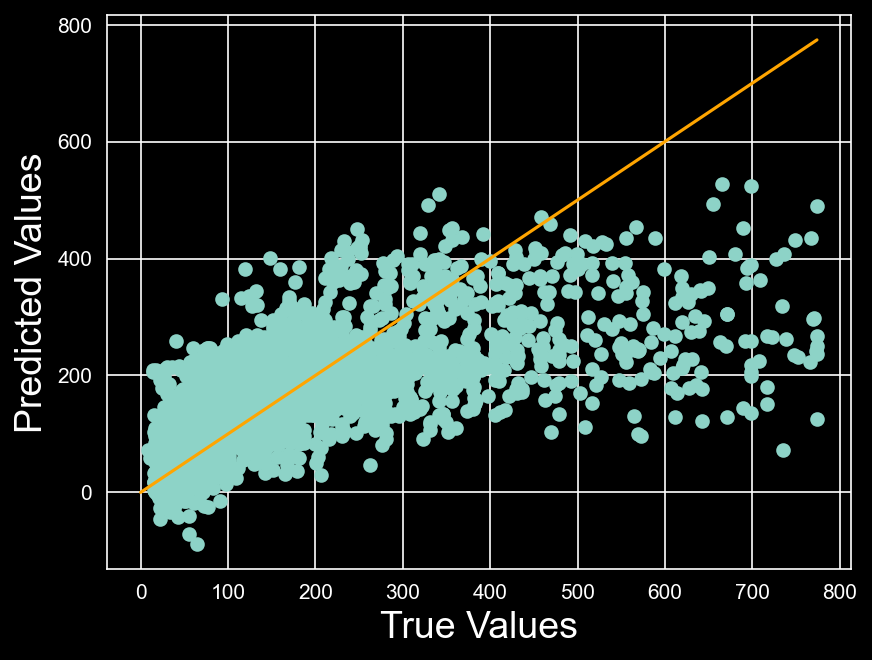

In [139]:
plt.scatter(y_testing_masked, predictions)
plt.plot([0, max(y_testing_masked)], [0, max(y_testing_masked)], color="orange")
plt.xlabel("True Values", fontsize=18)
plt.ylabel("Predicted Values", fontsize=18)

Text(0, 0.5, 'Count')

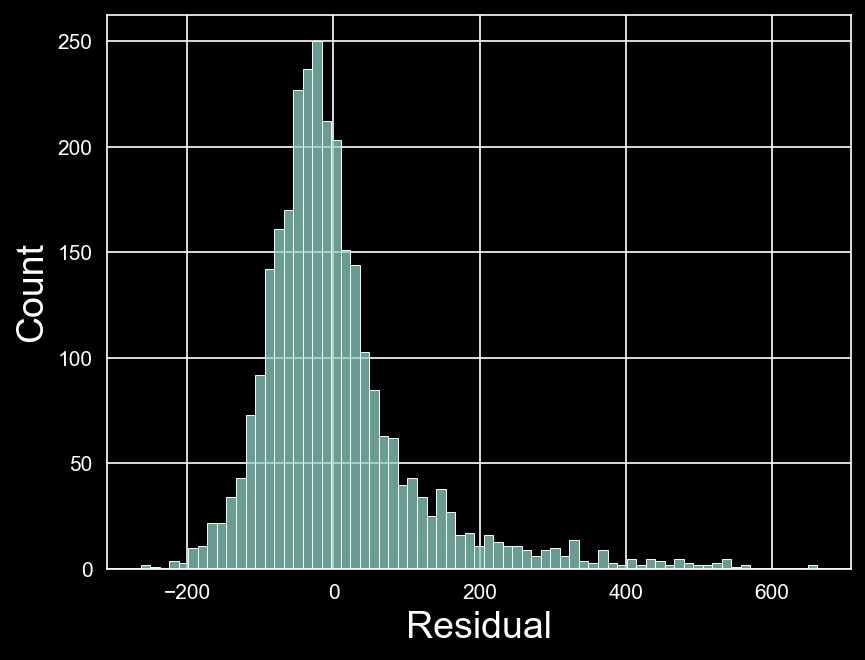

In [140]:
residuals = np.array(y_testing_masked) - np.array(predictions)

sns.histplot(data=residuals)
plt.xlabel("Residual", fontsize=18)
plt.ylabel("Count", fontsize=18)

## Complex Model Types

We will be slightly shifting around the ordering of these tasks to allow for the likely largest improvement (that being model choice) to be decided first before analyzing the complementary data

### DBSCAN

<Axes: xlabel='cluster', ylabel='price'>

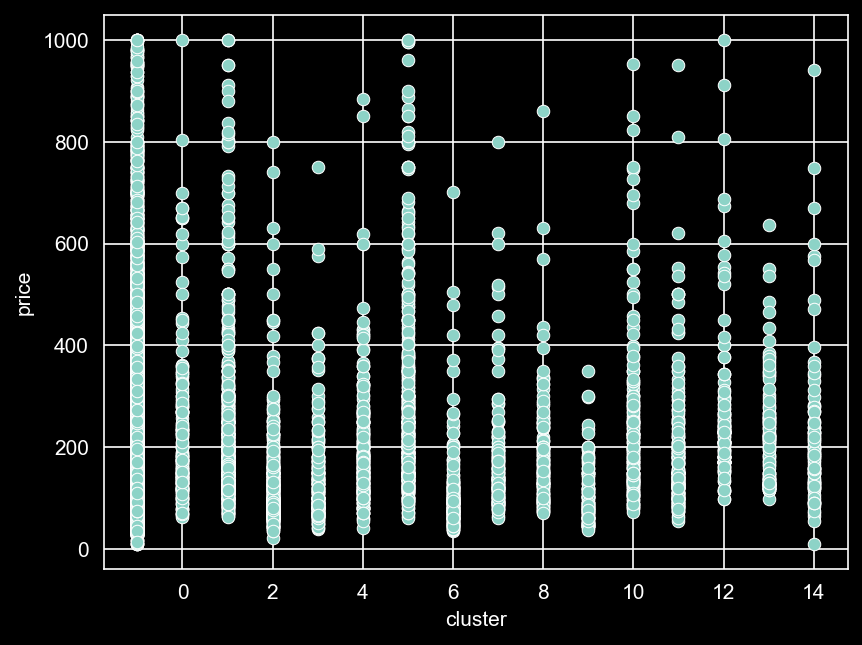

In [141]:
from sklearn.cluster import DBSCAN

X_listing_data = pd.get_dummies(engineered_features,
                                  columns = ['neighbourhood_group',
                                             'room_type','minimum_nights',
                                             'calculated_host_listings_count','number_of_reviews_ltm_binned','license_ose'],
                                             drop_first = True)

for col in X_listing_data.columns:
    if X_listing_data[col].dtype == 'bool':
        continue
    X_listing_data[col] = X_listing_data[col] / X_listing_data[col].max()


dbscan_clustering = ny_listing_clean.copy(True)

dbscan_clustering['cluster'] = DBSCAN(eps=1, min_samples=100).fit_predict(X_listing_data)

sns.scatterplot(x=dbscan_clustering['cluster'], y=dbscan_clustering['price'])

In [142]:
from sklearn.linear_model import SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from dataclasses import dataclass, field

### New Model Infrastructure

In [143]:
def validate_model(valid_model, features, labels, log_target=False, print_results=True):
    valid_y_pred = valid_model.predict(features)

    if log_target:
        # Only apply inverse log if the estimator did NOT already invert it.
        apply_inverse = True
        try:
            if isinstance(valid_model, Pipeline):
                inner = valid_model.named_steps.get('model', None)
                if isinstance(inner, TransformedTargetRegressor):
                    apply_inverse = False
            elif isinstance(valid_model, TransformedTargetRegressor):
                apply_inverse = False
        except Exception:
            pass
        if apply_inverse:
            valid_y_pred = np.expm1(valid_y_pred)

    valid_mae = mean_absolute_error(labels, valid_y_pred)
    valid_mape = mean_absolute_percentage_error(labels, valid_y_pred)
    valid_mse = mean_squared_error(labels, valid_y_pred)
    valid_rmse = np.sqrt(valid_mse)
    r2 = r2_score(labels, valid_y_pred)

    # Print the results
    if print_results:
        print(f"Mean Absolute Error (MAE): {valid_mae}")
        print(f"Mean Absolute Percentage Error: {valid_mape}")
        print(f"Mean Squared Error (MSE): {valid_mse}")
        print(f"Root Mean Squared Error (RMSE): {valid_rmse}")
        print(f"R-squared score: {r2}")
    
    return valid_mae, valid_mape, valid_mse, valid_rmse, r2

In [144]:
class DataDebugger(BaseEstimator, TransformerMixin):
    """
    A custom transformer to inspect data shape and content within a pipeline.
    """
    def __init__(self, name="DataDebugger", debug=True):
        self.name = name
        self.debug = debug

    def transform(self, data, y=None):
        if self.debug:
            print(f"--- {self.name} ---")
            print("Shape:", data.shape)
            if isinstance(data, pd.DataFrame) or isinstance(data, pd.Series):
                nan_rows = data[data.isnull().any(axis=1)]
                print(nan_rows.head())
            else:
                # For numpy arrays/other formats
                print(data[:5])
            print("------------------")
        
        # Return the data to continue the pipeline
        return data

    def fit(self, data, y=None, **fit_params):
        return self

In [145]:
@dataclass
class AirBnbConfig:
    debug: bool = False
    numerical_features: list[str] = field(default_factory=list)
    categorical_features: list[str] = field(default_factory=list)
    epsilon_frac: float = 0.001
    y_std: float = 1
    log_transform: bool = True

class AirBnbRegressor:
    def __init__(self, model=None, feature_pipe=None, config=AirBnbConfig(), name="Air BnB Regressor"):
        self.name = name

        if feature_pipe is None:
            self.feature_transformer = ColumnTransformer(transformers=[
                ('scaler', StandardScaler(), config.numerical_features),
                ('one-hot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), config.categorical_features)
            ], remainder='drop')
        else:
            self.feature_transformer = feature_pipe

        if model is None:
            self.model = SGDRegressor(loss='squared_error', epsilon=(config.epsilon_frac * config.y_std))
        else:
            self.model = model

        if config.log_transform:
            target_transformer = Pipeline([
                ('log', FunctionTransformer(func=np.log1p, inverse_func=np.expm1)),
                ('ts', StandardScaler())
            ])
            wrapped_model = TransformedTargetRegressor(regressor=self.model, transformer=target_transformer)
        else:
            wrapped_model = self.model

        if config.debug:
            self.pipeline = Pipeline(steps=[
                ('debug_init', DataDebugger(name="Initial Load", debug=config.debug)),
                ('feature_transform', self.feature_transformer),
                ('debug_feat', DataDebugger(name="Feature Transform", debug=config.debug)),
                ('model', wrapped_model)
            ])
        else:
            self.pipeline = Pipeline(steps=[
                ('feature_transform', self.feature_transformer),
                ('model', wrapped_model)
            ])
        
    def fit(self, X, y):
        self.pipeline.fit(X, y)
    
    def predict(self, X):
        return self.pipeline.predict(X)

    def validate(self, X, y, print_results=True):
        return validate_model(self.pipeline, X, y, print_results=print_results)

In [146]:
numerical_features = ["latitude", "longitude", "number_of_reviews", "availability_365", "neighbourhood_encoded", "last_review_delta"]
categorical_features = ["neighbourhood_group", "room_type", "minimum_nights", "calculated_host_listings_count", "number_of_reviews_ltm_binned", "license_ose"]

In [147]:
X, y = ny_listing_clean.drop(["price"], axis=1), ny_listing_clean["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [148]:
y_train_log = np.log1p(y_train)

config = AirBnbConfig(y_std=y_train_log.std(), numerical_features=numerical_features, categorical_features=categorical_features)

model = AirBnbRegressor(config=config)
model.fit(X_train, y_train)
_ = model.validate(X_test, y_test)


Mean Absolute Error (MAE): 71.62131317202686
Mean Absolute Percentage Error: 0.39852543091364184
Mean Squared Error (MSE): 14256.622993128065
Root Mean Squared Error (RMSE): 119.40110130617751
R-squared score: 0.36268454053177945


### Model Testing

#### SGDRegressor

In [149]:
loss_options = ["squared_error", "huber", "epsilon_insensitive", "squared_epsilon_insensitive"]

print(f"Model Metrics")
for loss in loss_options:
    test_model = SGDRegressor(loss=loss, epsilon=config.y_std * config.epsilon_frac)
    regressor = AirBnbRegressor(model=test_model, config=config)

    regressor.fit(X_train, y_train)
    mae, mape, _, rmse, r = regressor.validate(X_test, y_test, print_results=False)
    print(f"{loss}: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Model Metrics
squared_error: [71.79, 0.41, 118.64, 0.37]
huber: [97.48, 0.64, 153.78, -0.06]
epsilon_insensitive: [70.84, 0.37, 121.42, 0.34]
squared_epsilon_insensitive: [70.79, 0.39, 118.15, 0.38]


#### Decision Tree

In [150]:
criterion_options = ["squared_error", "friedman_mse", "absolute_error"]

print(f"Model Metrics")
for loss in criterion_options:
    test_model = DecisionTreeRegressor(criterion=loss)
    regressor = AirBnbRegressor(model=test_model, config=config)

    regressor.fit(X_train, y_train)
    mae, mape, _, rmse, r = regressor.validate(X_test, y_test, print_results=False)
    print(f"{loss}: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Model Metrics
squared_error: [85.43, 0.51, 143.86, 0.07]
friedman_mse: [86.76, 0.51, 147.44, 0.03]
absolute_error: [86.24, 0.49, 147.81, 0.02]


#### Random Forest

In [151]:
print(f"Model Metrics")
if not speed_flag:
    for loss in criterion_options:
        test_model = RandomForestRegressor(criterion=loss)
        regressor = AirBnbRegressor(model=test_model, config=config)

        regressor.fit(X_train, y_train)
        mae, mape, _, rmse, r = regressor.validate(X_test, y_test, print_results=False)
        print(f"{loss}: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Model Metrics
squared_error: [58.10, 0.31, 101.05, 0.54]
friedman_mse: [58.38, 0.31, 101.16, 0.54]
absolute_error: [58.27, 0.31, 101.37, 0.54]


#### MLP

In [152]:
activation_options = ["identity", "logistic", "tanh", "relu"]

print(f"Model Metrics")
hidden_layers = [40,40,40,40]
if not speed_flag:
    for activation in activation_options:
        test_model = MLPRegressor(loss='squared_error', activation=activation, max_iter=2000)
        regressor = AirBnbRegressor(model=test_model, config=config)

        regressor.fit(X_train, y_train)
        mae, mape, _, rmse, r = regressor.validate(X_test, y_test, print_results=False)
        print(f"{activation}: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Model Metrics
identity: [70.46, 0.39, 118.41, 0.37]
logistic: [64.95, 0.37, 107.37, 0.48]
tanh: [65.21, 0.36, 109.89, 0.46]
relu: [66.75, 0.37, 112.54, 0.43]


## Inclusion of Complementary Data

### NYPD Complaint Dataset

In [153]:
complaint_df = pd.read_csv("./data/nypd_complaint_filtered.csv", engine='python', on_bad_lines='skip', nrows=800000)
complaint_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 566394 entries, 0 to 566393
Data columns (total 36 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         566394 non-null  int64  
 1   CMPLNT_NUM         566394 non-null  object 
 2   CMPLNT_FR_DT       566394 non-null  object 
 3   CMPLNT_FR_TM       566394 non-null  object 
 4   CMPLNT_TO_DT       537977 non-null  object 
 5   CMPLNT_TO_TM       566394 non-null  object 
 6   ADDR_PCT_CD        566394 non-null  float64
 7   RPT_DT             566394 non-null  object 
 8   KY_CD              566394 non-null  int64  
 9   OFNS_DESC          566394 non-null  object 
 10  PD_CD              566050 non-null  float64
 11  PD_DESC            566394 non-null  object 
 12  CRM_ATPT_CPTD_CD   566394 non-null  object 
 13  LAW_CAT_CD         566394 non-null  object 
 14  BORO_NM            566394 non-null  object 
 15  LOC_OF_OCCUR_DESC  566394 non-null  object 
 16  PR

In [154]:
complaint_df["CMPLNT_FR_DT"] = pd.to_datetime(complaint_df["CMPLNT_FR_DT"], errors='coerce')

In [155]:
newest_date = complaint_df["CMPLNT_FR_DT"].max()
cutoff_date = newest_date - pd.DateOffset(years=1)

complaint_filter_df = complaint_df[complaint_df["CMPLNT_FR_DT"] >= cutoff_date]

In [156]:
complaint_filter_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 566394 entries, 0 to 566393
Data columns (total 36 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Unnamed: 0         566394 non-null  int64         
 1   CMPLNT_NUM         566394 non-null  object        
 2   CMPLNT_FR_DT       566394 non-null  datetime64[ns]
 3   CMPLNT_FR_TM       566394 non-null  object        
 4   CMPLNT_TO_DT       537977 non-null  object        
 5   CMPLNT_TO_TM       566394 non-null  object        
 6   ADDR_PCT_CD        566394 non-null  float64       
 7   RPT_DT             566394 non-null  object        
 8   KY_CD              566394 non-null  int64         
 9   OFNS_DESC          566394 non-null  object        
 10  PD_CD              566050 non-null  float64       
 11  PD_DESC            566394 non-null  object        
 12  CRM_ATPT_CPTD_CD   566394 non-null  object        
 13  LAW_CAT_CD         566394 non-null  object  

In [157]:
complaint_coords = complaint_filter_df[["Latitude", "Longitude"]]
complaint_coords = complaint_coords.dropna()
complaint_coords.head()

,Latitude,Longitude
0,40.819033,-73.918427
1,40.814731,-73.949202
2,40.757241,-73.968275
3,40.686371,-73.914592
4,40.746075,-73.864073


In [158]:
from sklearn.neighbors import BallTree

In [159]:
tree = BallTree(np.deg2rad(complaint_coords[["Latitude", "Longitude"]].values), metric="haversine")

In [160]:
earth_radius = 6371
search_radius = 1
results = tree.query_radius(np.deg2rad([[40.819033, -73.918427]]), r=search_radius/earth_radius)
len(results[0])

11600

In [161]:
ny_listing_coords = np.deg2rad(ny_listing_clean[["latitude","longitude"]])
results = tree.query_radius(ny_listing_coords, r=search_radius/earth_radius)
results

array([array([189637, 329490, 345855, ...,  47763, 355596, 563697],
             shape=(20999,))                                       ,
       array([ 39935,  62583, 115502, ..., 204678, 137853,  13921], shape=(4016,)),
       array([ 18908,  41650,  45879, ..., 234959,  38938, 350387],
             shape=(11833,))                                       , ...,
       array([181803, 336416,  67410, ..., 202702,  94981, 332190], shape=(2775,)),
       array([173127, 275337, 252323, ..., 515596, 531701, 532514], shape=(1230,)),
       array([448307, 251821, 105636, ..., 106152, 470197, 142953], shape=(9438,))],
      shape=(14740,), dtype=object)

In [162]:
complaint_counts = np.array([len(arr) for arr in results])
nypd_complaint_test = ny_listing_clean.copy()
nypd_complaint_test['complaint_count'] = complaint_counts

In [163]:
nypd_complementary_config = AirBnbConfig(numerical_features=numerical_features + ["complaint_count"], categorical_features=categorical_features)

print(f"Model Metrics")
if not speed_flag:
    orig_model = RandomForestRegressor(criterion="squared_error", n_estimators=200)
    orig_regressor = AirBnbRegressor(model=orig_model, config=config)
    test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200)
    test_regressor = AirBnbRegressor(model=test_model, config=nypd_complementary_config)

    X, y = nypd_complaint_test.drop(["price"], axis=1), nypd_complaint_test["price"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

    orig_regressor.fit(X_train, y_train)
    mae, mape, _, rmse, r = orig_regressor.validate(X_test, y_test, print_results=False)
    print(f"Original: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

    test_regressor.fit(X_train, y_train)
    mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
    print(f"NYPD Complaint: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Model Metrics
Original: [58.21, 0.31, 100.83, 0.55]
NYPD Complaint: [57.89, 0.31, 100.54, 0.55]


Now that we've established that there is an increase for using the NYPD complaint data I will do a short sweep of radius variable used to generate this data.

In [164]:
radius_sweep = [0.1, 0.25, 0.5, 1, 1.5, 2]

nypd_complaint_test = ny_listing_clean.copy()
for search_radius in radius_sweep:
    radius = search_radius/earth_radius

    results = tree.query_radius(np.deg2rad(ny_listing_clean[["latitude", "longitude"]]), r=radius)

    counts = np.array([len(arr) for arr in results])
    print(counts)
    nypd_complaint_test[f"complaint_{search_radius:.2f}km"] = counts
nypd_complaint_test

[ 86  76  52 ...  17  22 437]
[1362  307  965 ...   79  111 1411]
[7249 1479 3122 ...  580  312 3511]
[20999  4016 11833 ...  2775  1230  9438]
[32007  8574 20015 ...  7959  4818 21450]
[40670 13300 29610 ... 14720  7409 33098]


,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_encoded,last_review_delta,number_of_reviews_ltm_binned,license_ose,complaint_0.10km,complaint_0.25km,complaint_0.50km,complaint_1.00km,complaint_1.50km,complaint_2.00km
0,Manhattan,40.753560,-73.985590,Entire home/apt,240.0,30,47,0.24,3,289,2248.128826,1274.0,0,Unknown,86,1362,7249,20999,32007,40670
1,Brooklyn,40.709350,-73.953420,Entire home/apt,96.0,30,100,0.98,1,285,776.504133,190.0,3,Unknown,76,307,1479,4016,8574,13300
2,Manhattan,40.801070,-73.942550,Private room,59.0,30,1,0.02,2,83,162.614791,1290.0,0,Unknown,52,965,3122,11833,20015,29610
3,Manhattan,40.787780,-73.947590,Private room,73.0,30,100,1.28,1,186,165.985371,203.0,4,Unknown,104,941,2979,6680,13411,21111
5,Brooklyn,40.691940,-73.973890,Private room,216.0,2,100,2.21,2,0,197.470498,84.0,30,OSE,5,149,1084,6966,12839,17908
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35736,Manhattan,40.758164,-73.984037,Private room,299.0,1,6,6.00,3,329,864.214111,79.0,6,EXEMPT,187,1883,7198,20286,31222,38513
35817,Queens,40.673220,-73.727700,Private room,93.0,1,3,3.00,1,365,164.177126,78.0,3,Unknown,3,32,77,399,966,1752
35841,Brooklyn,40.675780,-73.967500,Private room,311.0,2,1,1.00,1,242,329.870027,79.0,1,OSE,17,79,580,2775,7959,14720
35856,Queens,40.746490,-73.830800,Private room,74.0,1,4,4.00,3,332,115.877922,81.0,4,OSE,22,111,312,1230,4818,7409


In [165]:
nypd_complaint_test["complaint_0.10km"]

0         86
1         76
2         52
3        104
5          5
        ... 
35736    187
35817      3
35841     17
35856     22
35918    437
Name: complaint_0.10km, Length: 14740, dtype: int64

In [166]:
counts_fields = ["complaint_0.10km", "complaint_0.25km", "complaint_1.00km", "complaint_1.50km", "complaint_2.00km"]

X, y = nypd_complaint_test.drop(["price"], axis=1), nypd_complaint_test["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

if not speed_flag:
    print(f"Model Metrics")
    orig_model = RandomForestRegressor(criterion="squared_error", n_estimators=200)
    orig_regressor = AirBnbRegressor(model=orig_model, config=config)

    orig_regressor.fit(X_train, y_train)
    mae, mape, _, rmse, r = orig_regressor.validate(X_test, y_test, print_results=False)
    print(f"Original: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

    for feature in counts_fields:
        nypd_complementary_config = AirBnbConfig(numerical_features=numerical_features + [feature], categorical_features=categorical_features)

        test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200)
        test_regressor = AirBnbRegressor(model=test_model, config=nypd_complementary_config)

        test_regressor.fit(X_train, y_train)
        mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
        print(f"NYPD Complaint <{feature}>: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Model Metrics
Original: [58.34, 0.31, 100.86, 0.55]
NYPD Complaint <complaint_0.10km>: [57.81, 0.31, 100.88, 0.55]
NYPD Complaint <complaint_0.25km>: [57.91, 0.31, 100.57, 0.55]
NYPD Complaint <complaint_1.00km>: [57.81, 0.31, 100.65, 0.55]
NYPD Complaint <complaint_1.50km>: [57.94, 0.31, 100.56, 0.55]
NYPD Complaint <complaint_2.00km>: [58.01, 0.31, 100.66, 0.55]


In [167]:
nypd_complementary_config = AirBnbConfig(numerical_features=numerical_features + counts_fields, categorical_features=categorical_features)

test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200)
test_regressor = AirBnbRegressor(model=test_model, config=nypd_complementary_config)

test_regressor.fit(X_train, y_train)
mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
print(f"NYPD Complaint <all>: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

NYPD Complaint <all>: [57.42, 0.31, 100.58, 0.55]


Some of the features seem to be less descriptive than others, but combined seems to give the best results thus we will keep the various radii options for this complementary dataset.

### Walkability Metric

In [168]:
import geopandas as gpd

In [169]:
gdb_path = "./data/Natl_WI.gdb"

In [170]:
gdf_airbnb = gpd.GeoDataFrame(
    ny_listing_clean,
    geometry=gpd.points_from_xy(ny_listing_clean["longitude"], ny_listing_clean["latitude"]),
    crs="EPSG:4326"
)

gdf_epa = gpd.read_file(gdb_path, layer=0)

gdf_airbnb_projected = gdf_airbnb.to_crs(gdf_epa.crs)

geospatial_test = gpd.sjoin(gdf_airbnb_projected, gdf_epa, how="left", predicate="within")

In [171]:
geospatial_test.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 14740 entries, 0 to 35918
Data columns (total 45 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   neighbourhood_group             14740 non-null  category
 1   latitude                        14740 non-null  float64 
 2   longitude                       14740 non-null  float64 
 3   room_type                       14740 non-null  category
 4   price                           14740 non-null  float64 
 5   minimum_nights                  14740 non-null  category
 6   number_of_reviews               14740 non-null  int64   
 7   reviews_per_month               14740 non-null  float64 
 8   calculated_host_listings_count  14740 non-null  category
 9   availability_365                14740 non-null  int64   
 10  neighbourhood_encoded           14740 non-null  float64 
 11  last_review_delta               14740 non-null  float64 
 12  number_of_revie

Now that we have geospatially joined our EPA Walkability data to our Airbnb data we are going to run a quick test to see if any of these metrics help improve our results. We will validate them one at a time and take any that help improve our metrics. We would expect metrics such as `NatWalkInd` and `D3B` to have some power as these are the direct metrics we were looking for, but perhaps there are some other strong predictors in here.

In [172]:
geo_columns = geospatial_test.select_dtypes("float64").columns[6:]

X, y = geospatial_test.drop(["price"], axis=1), geospatial_test["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

if not speed_flag:
    print(f"Model Metrics")
    orig_model = RandomForestRegressor(criterion="squared_error", n_estimators=200)
    orig_regressor = AirBnbRegressor(model=orig_model, config=config)

    orig_regressor.fit(X_train, y_train)
    mae, mape, _, rmse, r = orig_regressor.validate(X_test, y_test, print_results=False)
    print(f"Original: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

    for feature in geo_columns:
        geospatial_config = AirBnbConfig(numerical_features=numerical_features + [feature], categorical_features=categorical_features)

        test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200)
        test_regressor = AirBnbRegressor(model=test_model, config=geospatial_config)

        test_regressor.fit(X_train, y_train)
        mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
        print(f"Geo Data <{feature}>: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Model Metrics
Original: [58.31, 0.31, 101.05, 0.54]
Geo Data <Ac_Total>: [58.08, 0.31, 100.92, 0.54]
Geo Data <Ac_Water>: [58.20, 0.31, 101.11, 0.54]
Geo Data <Ac_Land>: [58.23, 0.31, 101.29, 0.54]
Geo Data <Ac_Unpr>: [58.33, 0.31, 100.95, 0.54]
Geo Data <CountHU>: [58.41, 0.31, 101.41, 0.54]
Geo Data <HH>: [58.53, 0.31, 101.49, 0.54]
Geo Data <D2B_E8MIXA>: [57.97, 0.31, 100.78, 0.55]
Geo Data <D2A_EPHHM>: [58.18, 0.31, 101.24, 0.54]
Geo Data <D3B>: [58.06, 0.31, 101.16, 0.54]
Geo Data <D4A>: [57.87, 0.31, 100.44, 0.55]
Geo Data <D2A_Ranked>: [58.14, 0.31, 100.83, 0.55]
Geo Data <D2B_Ranked>: [58.10, 0.31, 100.85, 0.55]
Geo Data <D3B_Ranked>: [58.03, 0.31, 100.72, 0.55]
Geo Data <D4A_Ranked>: [58.22, 0.31, 101.07, 0.54]
Geo Data <NatWalkInd>: [58.15, 0.31, 101.08, 0.54]
Geo Data <Shape_Length>: [58.09, 0.31, 100.99, 0.54]
Geo Data <Shape_Area>: [58.24, 0.31, 101.11, 0.54]


Given the results of our previous experiments, it's relatively safe to say that this dataset wasn't as fruitful as our NYPD data, but it still has a couple small metrics that performed. We will be ignoring certain metrics that have no reason to be predictors such as the `Shape_` data as that's just describing the shapes for the GDB polygon format.

From this result we are going to test the result of `CountHU`, `D3B`, and `NatWalkInd`. These are measures of the number of housing units in the area, the number of walkable intersections, and the general walkability index.

In [173]:
select_geo_columns = ["CountHU", "D3B", "NatWalkInd"]

geospatial_config = AirBnbConfig(numerical_features=numerical_features + select_geo_columns, categorical_features=categorical_features)

test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200, random_state=0)
test_regressor = AirBnbRegressor(model=test_model, config=geospatial_config)

test_regressor.fit(X_train, y_train)
mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
print(f"Geo Data <CountHU, D3B, NatWalkInd>: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Geo Data <CountHU, D3B, NatWalkInd>: [58.11, 0.31, 101.14, 0.54]


These didn't provide great metrics, but we will include them for now along with the other optimizations.

### Reintroducing Engineered Features

In [174]:
engineered_features_test = ny_listing_clean.copy()

# Polar Coords
engineered_features_test["polar_radius"] = engineered_features["polar_radius"]
engineered_features_test["polar_theta"] = engineered_features["polar_theta"]

# Normalized reviews per stay
engineered_features_test["normalized_reviews_per_stay"] = engineered_features["normalized_reviews_per_stay"]

In [175]:
X, y = engineered_features_test.drop(["price"], axis=1), engineered_features_test["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

engineered_features_columns = ["polar_radius", "polar_theta"]

engineered_config = AirBnbConfig(numerical_features=numerical_features + engineered_features_columns, 
                                 categorical_features=categorical_features)

test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200, random_state=0)
test_regressor = AirBnbRegressor(model=test_model, config=engineered_config)

test_regressor.fit(X_train, y_train)
mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
print(f"Geo Data <Polar>: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

engineered_config = AirBnbConfig(numerical_features=numerical_features + ["normalized_reviews_per_stay"], 
                                 categorical_features=categorical_features)

test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200, random_state=0)
test_regressor = AirBnbRegressor(model=test_model, config=engineered_config)

test_regressor.fit(X_train, y_train)
mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
print(f"Geo Data <Reviews Per Stay>: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

Geo Data <Polar>: [58.19, 0.31, 100.88, 0.55]
Geo Data <Reviews Per Stay>: [58.45, 0.31, 101.01, 0.54]


From this analysis it seems that the polar coordinates could prove to be a useful metric. This makes some sense as essentially a large polar radius means you are further away from the epicenter of the city.

### New dataset collection

In [176]:
ny_listing_complementary = ny_listing_clean.copy()

In [177]:
for count in counts_fields:
    ny_listing_complementary[count] = nypd_complaint_test[count]

for geo in select_geo_columns:
    ny_listing_complementary[geo] = geospatial_test[geo]

for polar in engineered_features_columns:
    ny_listing_complementary[polar] = engineered_features_test[polar]

In [178]:
ny_listing_complementary.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14740 entries, 0 to 35918
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   neighbourhood_group             14740 non-null  category
 1   latitude                        14740 non-null  float64 
 2   longitude                       14740 non-null  float64 
 3   room_type                       14740 non-null  category
 4   price                           14740 non-null  float64 
 5   minimum_nights                  14740 non-null  category
 6   number_of_reviews               14740 non-null  int64   
 7   reviews_per_month               14740 non-null  float64 
 8   calculated_host_listings_count  14740 non-null  category
 9   availability_365                14740 non-null  int64   
 10  neighbourhood_encoded           14740 non-null  float64 
 11  last_review_delta               14740 non-null  float64 
 12  number_of_reviews_ltm_b

## Baseline to Best Model Summarization

Now that we have combined all of our potential design decisions it is time for some tuning of the hyperparameters of our model. In our case that means sweep through all the potential options of the `RandomForestRegressor` with all of our new data included.

In [179]:
ny_listing_complementary.select_dtypes(["float64", "int64"]).columns

Index(['latitude', 'longitude', 'price', 'number_of_reviews',
       'reviews_per_month', 'availability_365', 'neighbourhood_encoded',
       'last_review_delta', 'complaint_0.10km', 'complaint_0.25km',
       'complaint_1.00km', 'complaint_1.50km', 'complaint_2.00km', 'CountHU',
       'D3B', 'NatWalkInd', 'polar_radius', 'polar_theta'],
      dtype='object')

In [180]:
X, y = ny_listing_complementary.drop(["price"], axis=1), ny_listing_complementary["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [181]:
full_numerical_features = X.select_dtypes(["float64", "int64"]).columns
full_categorical_features = X.select_dtypes("category").columns

final_config = AirBnbConfig(numerical_features=full_numerical_features, 
                            categorical_features=full_categorical_features,
                            log_transform=True)

In [182]:
model = RandomForestRegressor(n_estimators=200, criterion="squared_error", random_state=0)
regressor = AirBnbRegressor(model=model, config=final_config)

In [183]:
regressor.fit(X_train, y_train)
_ = regressor.validate(X_test, y_test)

Mean Absolute Error (MAE): 57.948232757806274
Mean Absolute Percentage Error: 0.31107901481306466
Mean Squared Error (MSE): 10356.088034609405
Root Mean Squared Error (RMSE): 101.76486640589377
R-squared score: 0.5370506039717967


In [184]:
regressor.pipeline

,steps,"[('feature_transform', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('scaler', ...), ('one-hot', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [185]:
import warnings
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn import metrics
warnings.filterwarnings('ignore')

param_grid = {
    "model__regressor__n_estimators" : [10,50,100,200],
    "model__regressor__min_samples_leaf" : [1, 2, 3],
    "model__regressor__ccp_alpha": [0.0, 0.001, 0.005, 0.01, 0.1],
}

if not speed_flag:
    # Run GridSearchCV (use neg_root_mean_squared_error for RMSE approximation)
    gs = GridSearchCV(regressor.pipeline, param_grid, cv=3, n_jobs=-1, scoring='neg_root_mean_squared_error', verbose=2)
    gs.fit(X_train, y_train)
    print('Best params:', gs.best_params_)
    print('Best CV score (neg RMSE):', gs.best_score_)


Fitting 3 folds for each of 60 candidates, totalling 180 fits
[CV] END model__regressor__ccp_alpha=0.0, model__regressor__min_samples_leaf=1, model__regressor__n_estimators=10; total time=   1.2s
[CV] END model__regressor__ccp_alpha=0.0, model__regressor__min_samples_leaf=1, model__regressor__n_estimators=10; total time=   1.2s
[CV] END model__regressor__ccp_alpha=0.0, model__regressor__min_samples_leaf=1, model__regressor__n_estimators=10; total time=   1.2s
[CV] END model__regressor__ccp_alpha=0.0, model__regressor__min_samples_leaf=2, model__regressor__n_estimators=10; total time=   1.0s
[CV] END model__regressor__ccp_alpha=0.0, model__regressor__min_samples_leaf=2, model__regressor__n_estimators=10; total time=   1.0s
[CV] END model__regressor__ccp_alpha=0.0, model__regressor__min_samples_leaf=2, model__regressor__n_estimators=10; total time=   1.0s
[CV] END model__regressor__ccp_alpha=0.0, model__regressor__min_samples_leaf=1, model__regressor__n_estimators=50; total time=   5.9s


The end result from this grid search isn't terribly surprising. It basically confirms that having a large number of estimators with no `ccp_alpha` leads to the best results. This matches expectations since we aren't suffering from overfitting given our gap from the true predicted values.

In [186]:
y_pred = regressor.predict(X_test)

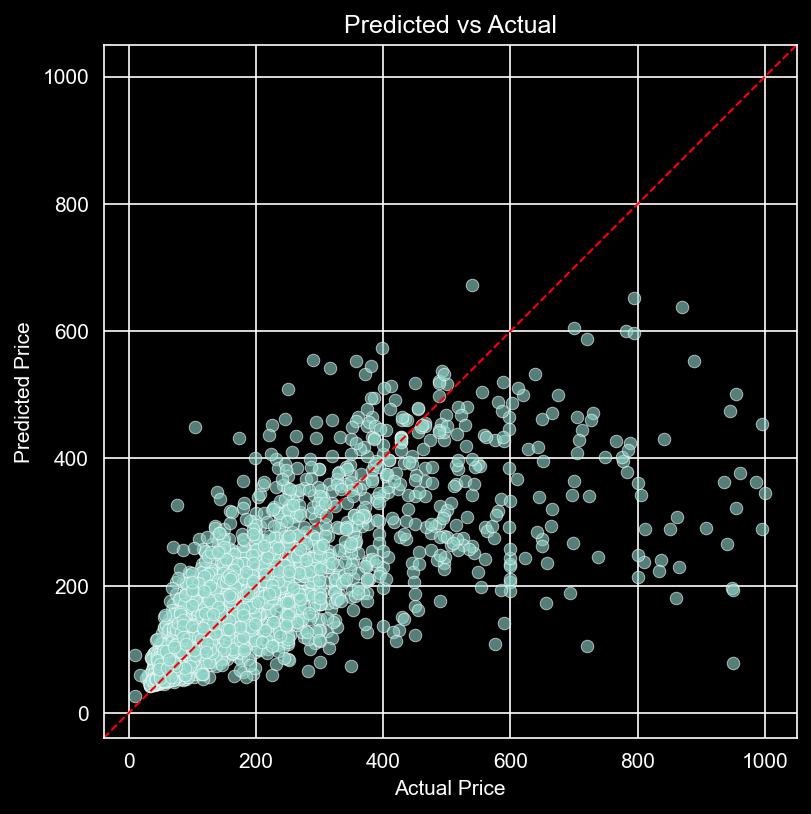

In [187]:
# Seaborn fitted vs predicted
plt.figure(figsize=(6,6))
ax = sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
# Add identity line y = x
lims = (
    min(ax.get_xlim()[0], ax.get_ylim()[0]),
    max(ax.get_xlim()[1], ax.get_ylim()[1])
)
ax.plot(lims, lims, '--', color='red', linewidth=1)
# Set equal aspect and matching limits
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect('equal', adjustable='box')

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Predicted vs Actual")
plt.show()

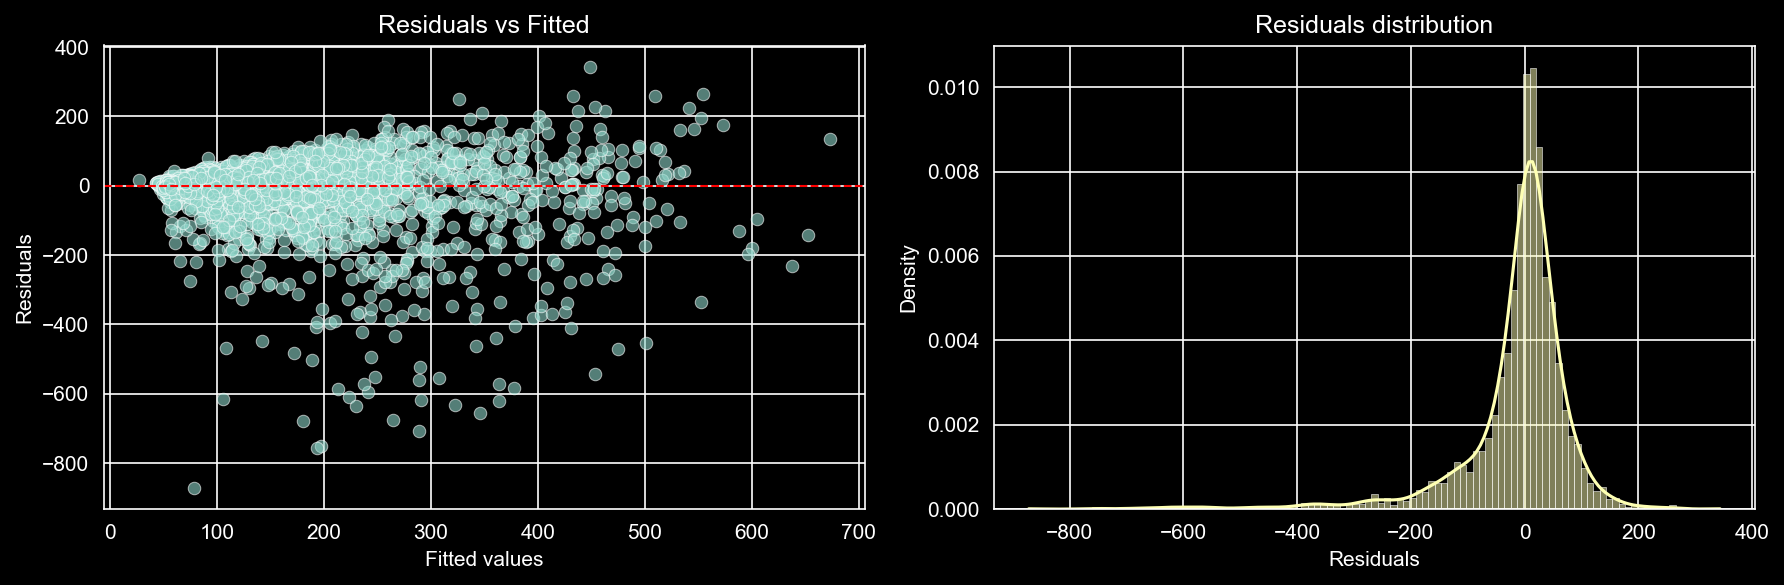

In [188]:
# Seaborn residual diagnostics using the fitted model
residuals = y_pred - y_test

fig, axes = plt.subplots(ncols=2, figsize=(12,4))

# Residuals vs Fitted
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

# Residual distribution (hist + KDE)
sns.histplot(residuals, kde=True, stat="density", ax=axes[1], color="C1")
axes[1].set_title('Residuals distribution')
axes[1].set_xlabel('Residuals')

plt.tight_layout()
plt.show()

## Simplify Model

In [189]:
numerical_prune = ["CountHU", "neighbourhood_encoded", "NatWalkInd", "complaint_1.50km",
                   "complaint_0.25km", "D3B", "number_of_reviews", "complaint_0.10km"]
categorical_prune = ["number_of_reviews_ltm_binned", "neighbourhood_group"]

pruned_numerical_features = [feature for feature in full_numerical_features if feature not in numerical_prune]
pruned_categorical_features = [feature for feature in full_categorical_features if feature not in categorical_prune]

min_mae = ("orig", 200)
if not speed_flag:
    print(f"Model Metrics")
    orig_config = AirBnbConfig(numerical_features=pruned_numerical_features,
                               categorical_features=pruned_categorical_features)

    orig_model = RandomForestRegressor(criterion="squared_error", n_estimators=200, random_state=0)
    orig_regressor = AirBnbRegressor(model=orig_model, config=orig_config)

    orig_regressor.fit(X_train, y_train)
    mae, mape, _, rmse, r = orig_regressor.validate(X_test, y_test, print_results=False)
    print(f"Original: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")

    for feature in pruned_numerical_features:
        num_features_test = [x for x in pruned_numerical_features if x != feature]
        cat_features_test = pruned_categorical_features

        test_config = AirBnbConfig(numerical_features=num_features_test,
                                   categorical_features=cat_features_test)

        test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200, random_state=0)
        test_regressor = AirBnbRegressor(model=test_model, config=test_config)

        test_regressor.fit(X_train, y_train)
        mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
        print(f"<{feature}> Removed: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")
        if mae < min_mae[1]:
            min_mae = (feature, mae)

    for feature in pruned_categorical_features:
        num_features_test = pruned_numerical_features
        cat_features_test = [x for x in pruned_categorical_features if x != feature]

        test_config = AirBnbConfig(numerical_features=num_features_test,
                                   categorical_features=cat_features_test)

        test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200, random_state=0)
        test_regressor = AirBnbRegressor(model=test_model, config=test_config)

        test_regressor.fit(X_train, y_train)
        mae, mape, _, rmse, r = test_regressor.validate(X_test, y_test, print_results=False)
        print(f"<{feature}> Removed: [{mae:.2f}, {mape:.2f}, {rmse:.2f}, {r:.2f}]")
        if mae < min_mae[1]:
            min_mae = (feature, mae)

print(f"Smallest MAE: <{min_mae[0]}> {min_mae[1]}")



Model Metrics
Original: [57.42, 0.31, 100.90, 0.54]
<latitude> Removed: [57.61, 0.31, 100.78, 0.55]
<longitude> Removed: [57.79, 0.31, 101.14, 0.54]
<reviews_per_month> Removed: [57.46, 0.31, 100.38, 0.55]
<availability_365> Removed: [58.13, 0.31, 102.58, 0.53]
<last_review_delta> Removed: [58.25, 0.31, 101.91, 0.54]
<complaint_1.00km> Removed: [57.59, 0.31, 100.84, 0.55]
<complaint_2.00km> Removed: [57.46, 0.31, 100.66, 0.55]
<polar_radius> Removed: [57.69, 0.31, 101.43, 0.54]
<polar_theta> Removed: [57.28, 0.31, 100.66, 0.55]
<room_type> Removed: [64.69, 0.39, 109.41, 0.46]
<minimum_nights> Removed: [57.41, 0.31, 100.97, 0.54]
<calculated_host_listings_count> Removed: [59.51, 0.33, 103.58, 0.52]
<license_ose> Removed: [57.80, 0.31, 100.81, 0.55]
Smallest MAE: <polar_theta> 57.2803450976888


In [190]:
def get_pruned_model(numerical_prune, categorical_prune):
    pruned_numerical_features = [feature for feature in full_numerical_features if feature not in numerical_prune]
    pruned_categorical_features = [feature for feature in full_categorical_features if feature not in categorical_prune]

    test_config = AirBnbConfig(numerical_features=pruned_numerical_features,
                                categorical_features=pruned_categorical_features)

    test_model = RandomForestRegressor(criterion="squared_error", n_estimators=200, random_state=0)
    test_regressor = AirBnbRegressor(model=test_model, config=test_config)

    test_regressor.fit(X_train, y_train)

    return test_regressor


In [191]:
potential_removal = {
    "numerical_minimal" : ["CountHU", "neighbourhood_encoded", "NatWalkInd", "complaint_1.50km"],
    "categorical_minimal" : ["number_of_reviews_ltm_binned"],
    "nuemerical_aggressive" : numerical_prune,
    "categorical_aggressive" : categorical_prune
}
potential_removal

{'numerical_minimal': ['CountHU',
  'neighbourhood_encoded',
  'NatWalkInd',
  'complaint_1.50km'],
 'categorical_minimal': ['number_of_reviews_ltm_binned'],
 'nuemerical_aggressive': ['CountHU',
  'neighbourhood_encoded',
  'NatWalkInd',
  'complaint_1.50km',
  'complaint_0.25km',
  'D3B',
  'number_of_reviews',
  'complaint_0.10km'],
 'categorical_aggressive': ['number_of_reviews_ltm_binned',
  'neighbourhood_group']}

In [192]:
final_model = get_pruned_model(potential_removal["numerical_minimal"], potential_removal["categorical_minimal"])
final_model

With this process of selecting features to remove we were able to identify a couple of features that were not predictive and leading overfitting which are now saved in the `_minimal` feature set to be removed if wanted. There is an alternate `_aggressive`, which loses approximately 1 percent MAPE and removes another 5 or so features.

## Applicability of Model